# DSAI4205 Big Data Analytics - Group Project
## Dataset 5: Twitter Entity-Level Sentiment Analysis
### Interim Technical Notebook - EDA, Data Cleaning and TF-IDF + Logistic Regression Baseline

**Group 8 - ChillGuy**

| Name | Student ID |
|---|---|
| Chao Ka Kin | 23021004D |
| Leung Wai Tsun | 24097714D |
| LIANG Zijian | 24082468D |
| Lam Kin Ho | 24084386D |
| Yeung Tsz Chun Herman | 23019365D |

---

### How to read this notebook

This notebook is the **technical deliverable** for the interim submission. It is organised in the
same order as the written report:

| Section | Content | Report section |
|---|---|---|
| 0 | Setup and reproducibility | 9 |
| 1 | Load data and inspect the raw files | 2 |
| 2 | Exploratory Data Analysis | 3 |
| 3 | Data cleaning pipeline | 4 |
| 4 | Baseline model: TF-IDF + Logistic Regression | 5 |
| 5 | Error analysis | 6 |
| 6 | Findings and open questions | 7 |

Every figure and number in the written report is produced by the cells below.
The notebook is deterministic: the random seed is fixed at 42 throughout.


In [1]:
# --- Run-All setup: dependencies + repository root ---
import importlib
import importlib.util
import os
import subprocess
import sys
from pathlib import Path

# 1) Small packages the notebook needs, installed into the SAME interpreter
#    that runs this kernel (so it works even if Jupyter uses another Python).
for module, package in [
    ("nltk", "nltk"),
    ("ftfy", "ftfy"),
    ("wordcloud", "wordcloud"),
    ("seaborn", "seaborn"),
]:
    if importlib.util.find_spec(module) is None:
        print(f"Installing {package} ...")
        try:
            subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", package])
        except Exception:
            subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", "--user", package])
importlib.invalidate_caches()

# 2) NLTK corpora used by the cleaning and lexicon steps.
import nltk
for corpus, folder in [
    ("vader_lexicon", "sentiment"),
    ("wordnet", "corpora"),
    ("omw-1.4", "corpora"),
    ("stopwords", "corpora"),
]:
    try:
        nltk.data.find(f"{folder}/{corpus}")
    except LookupError:
        nltk.download(corpus, quiet=True)

# 3) Locate the repository root so relative paths work regardless of cwd.
def _find_repo_root(start: Path) -> Path:
    for p in [start, *start.parents]:
        if (p / "src" / "embeddings_common.py").exists():
            return p
    return start


ROOT = _find_repo_root(Path.cwd().resolve())
os.chdir(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
print("Dependencies checked. Repository root located.")

Dependencies checked. Repository root located.


> **Run All is supported.**
> The first cell installs `ftfy`, `wordcloud`, `seaborn` and the NLTK data into
> the kernel you are using (if they are missing), then locates the repository
> root. Part II embeds the five model scripts as function definitions;
> **Run All does not retrain them**. Results are displayed from the checked-in
> artefacts in `models/` and `data/processed/`, and the EDA/baseline sections
> in Part I do run.

---
## 0. Setup and reproducibility

We pin the random seed and define the project paths once, so that re-running the notebook
top-to-bottom reproduces every result exactly.


In [2]:
import json
import re
import sys
import warnings
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore")

# ---------------------------------------------------------------- reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 110)

# ---------------------------------------------------------------- paths
ROOT = Path.cwd()
DATA_DIR = ROOT / "Data 5 - Twitter" / "Data 5 - Twitter"
TRAIN_CSV = DATA_DIR / "traindata.csv"
TEST_CSV = DATA_DIR / "testdata.csv"
PROC = ROOT / "data" / "processed"
FIG = ROOT / "reports" / "figures"

# import our own cleaning module so the notebook and the pipeline cannot diverge
sys.path.insert(0, str(ROOT / "src"))
import text_clean as tc

print("Python      :", sys.version.split()[0])
print("pandas      :", pd.__version__)
print("numpy       :", np.__version__)
print("matplotlib  :", matplotlib.__version__)
print("seaborn     :", sns.__version__)


Python      : 3.14.0
pandas      : 3.0.2
numpy       : 2.4.4
matplotlib  : 3.10.7
seaborn     : 0.13.2


In [3]:
import sklearn
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

print("scikit-learn:", sklearn.__version__)

plt.rcParams.update({
    "figure.dpi": 110,
    "figure.figsize": (10, 4.2),
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 9,
})
sns.set_theme(style="whitegrid", context="notebook")

LABEL_NAMES = {0: "Negative", 1: "Positive", 2: "Irrelevant", 3: "Neutral"}
PALETTE = {0: "#D62728", 1: "#2CA02C", 2: "#7F7F7F", 3: "#1F77B4"}


scikit-learn: 1.9.1


---
## 1. Load the data and understand what we were given

### 1.1 Business framing

The brief asks for a **decision support system that classifies text**. For Twitter sentiment the
practical use is brand and product monitoring: route complaints, spot emerging product failures,
and separate genuine opinion from unrelated chatter.

### 1.2 Type of data and granularity

- **Type:** unstructured text (`Phrase`) plus a categorical target (`Sentiment`).
- **Granularity:** one row = one tweet. Tweets are truncated at roughly 350 characters.
- **No identifiers:** there is no user, timestamp, or entity column.

That last point matters more than it first appears - we return to it in the findings.


In [4]:
train_raw = pd.read_csv(TRAIN_CSV, encoding="utf-8-sig")
test_raw = pd.read_csv(TEST_CSV, encoding="utf-8-sig")

print(f"traindata.csv : {train_raw.shape[0]:>4} rows x {train_raw.shape[1]} columns")
print(f"testdata.csv  : {test_raw.shape[0]:>4} rows x {test_raw.shape[1]} columns")
print()
print("Columns in traindata.csv:", list(train_raw.columns))
print("Columns in testdata.csv :", list(test_raw.columns))
print()
print("dtypes:")
print(train_raw.dtypes.to_string())
print()
train_raw.head(8)


traindata.csv :  596 rows x 2 columns
testdata.csv  :  397 rows x 2 columns

Columns in traindata.csv: ['Phrase', 'Sentiment']
Columns in testdata.csv : ['Phrase', 'Sentiment']

dtypes:
Phrase           str
Sentiment    float64



,Phrase,Sentiment
0,wishin I could go to home depot to buy shit to build shit,0.0
1,"@ verizon I'm having great difficulty getting access to past bills. If I can't find what I need, then I'll...",0.0
2,"Please don't believe the rumors that I'm a ""Champions League player"" or ""ugly"" because I'm afraid I won't ...",0.0
3,@PUBG PLEASE SORT OUT AND NEWS CRASHES!,0.0
4,Features Fix the errors in the new GTA Mark V updates,0.0
5,Disrespectful. â?Plain and deadly simple.,0.0
6,I thought the game was damn near done wtf going on,0.0
7,"Fucking hell, you those guys who are alrdy making a lots of honest money. That Greed is good.",0.0


### 1.3 The schema does not match the documentation

The supplied `Twitter Sentiment Analysis Dataset.docx` states:

> "This is an **entity-level** sentiment analysis dataset of twitter. Given a **message and an
> entity**, the task is to judge the sentiment of the message **about the entity**. There are four
> classes: Negative, Positive, Irrelevant and Neutral."

But the delivered CSVs contain **only two columns** - `Phrase` and `Sentiment`. There is **no entity
column**.

This is not a cosmetic detail. "Irrelevant" is defined as *"the message is not about the entity"*.
With no entity recorded, that label cannot be applied consistently - not by a human annotator and
certainly not by a model. We document the deviation rather than silently inventing an entity.

Let us verify this programmatically so the finding is evidenced, not asserted.


In [5]:
expected_beyond_phrase_and_label = [
    c for c in list(train_raw.columns) + list(test_raw.columns)
    if c.lower() in {"entity", "topic", "brand", "company", "subject"}
]

print("Entity-like columns found:", expected_beyond_phrase_and_label or "NONE")
print()
print("Documentation promises : message + ENTITY -> 4-class verdict")
print("Delivered columns      :", list(train_raw.columns))
print()
print("=> The 'Irrelevant' label is defined relative to information that is absent from the file.")


Entity-like columns found: NONE

Documentation promises : message + ENTITY -> 4-class verdict
Delivered columns      : ['Phrase', 'Sentiment']

=> The 'Irrelevant' label is defined relative to information that is absent from the file.


### 1.4 Missing values, duplicates and label domain

Before any modelling we need to know what is broken. We check missing values, blank strings,
exact duplicates, contradictory labels, and whether the label domain matches the documented 0-3.


In [6]:
def audit(df: pd.DataFrame, name: str) -> pd.DataFrame:
    """Compact data-quality audit of one raw file."""
    ph = df["Phrase"].astype(str)
    rows = {
        "rows": len(df),
        "missing Phrase": int(df["Phrase"].isna().sum()),
        "missing Sentiment": int(df["Sentiment"].isna().sum()),
        "blank after strip": int((ph.str.strip() == "").sum()),
        "exact duplicate rows": int(df.duplicated().sum()),
        "duplicate Phrase text": int(df.duplicated(subset=["Phrase"]).sum()),
        "Phrase with >1 label": int(df.groupby("Phrase")["Sentiment"].nunique().gt(1).sum()),
        "invalid labels (outside 0-3)": int((~df["Sentiment"].isin([0, 1, 2, 3])).sum()),
        "labels observed": sorted(df["Sentiment"].dropna().unique().tolist()),
        "Sentiment dtype": str(df["Sentiment"].dtype),
    }
    return pd.DataFrame({"check": list(rows), name: list(rows.values())}).set_index("check")


audit_table = audit(train_raw, "train").join(audit(test_raw, "test"), how="left")
display(audit_table)


,train,test
check,,
rows,596,397
missing Phrase,0,0
missing Sentiment,0,0
blank after strip,0,0
exact duplicate rows,3,0
duplicate Phrase text,4,0
Phrase with >1 label,1,0
invalid labels (outside 0-3),0,0
labels observed,"[0.0, 1.0, 2.0, 3.0]","[0, 1, 2, 3]"


**Interpretation.** There are **no missing values and no invalid labels**, which is good. But there
*are* duplicates, and one phrase carries two different labels. We also notice the label dtype is
inconsistent (`float64` in train because of the `0.0` formatting, `int64` in test) - trivial, but it
will silently break any naive concatenation of the two files, so it must be standardised.

### 1.5 Text-level quality defects

Beyond the tabular checks, text carries its own class of defects. We scan for the artefacts that
actually damage tokenisation.


In [7]:
ph = train_raw["Phrase"].astype(str)

defect_checks = {
    "Mojibake (double-encoded UTF-8)": r"[ÃÂâ]",
    "Non-ASCII characters": r"[^\x00-\x7F]",
    "<unk> placeholder": None,
    "Embedded URLs": r"https?://|www\.",
    "@mentions": None,
    "HTML-like tags": r"<(?!unk>)[^<>]{1,30}>",
    "Anonymiser token 'RhandlerR'": None,
    "ALL-CAPS shouting (3+)": r"\b[A-Z]{3,}\b",
    "Ellipses (2+ dots)": r"\.{2,}",
}

results = []
for label, pattern in defect_checks.items():
    if pattern is None:
        needle = {"<unk> placeholder": "<unk>", "@mentions": "@",
                  "Anonymiser token 'RhandlerR'": "RhandlerR"}[label]
        n = int(ph.str.contains(needle, regex=False).sum())
    else:
        n = int(ph.str.contains(pattern, regex=True).sum())
    results.append({"defect": label, "rows": n, "pct": round(n / len(ph) * 100, 1)})

defects = pd.DataFrame(results).sort_values("rows", ascending=False).reset_index(drop=True)
display(defects)

print("Example of mojibake (the bytes for a curly apostrophe were decoded as cp1252):")
for s in ph[ph.str.contains(r"[ÃÂâ]", regex=True)].head(2):
    print("   ", s[:105])


,defect,rows,pct
0,ALL-CAPS shouting (3+),171,28.7
1,@mentions,166,27.9
2,Ellipses (2+ dots),152,25.5
3,Non-ASCII characters,99,16.6
4,Mojibake (double-encoded UTF-8),94,15.8
5,<unk> placeholder,26,4.4
6,Embedded URLs,23,3.9
7,Anonymiser token 'RhandlerR',6,1.0
8,HTML-like tags,1,0.2


Example of mojibake (the bytes for a curly apostrophe were decoded as cp1252):
    Disrespectful. â?Plain and deadly simple.
    Nerd Tweet: Iâm getting really disappointed with @PlayOverwatch one of my favourite heroes that I have 


**What mojibake actually is.** The file was written as UTF-8 but read as cp1252, so a single curly
apostrophe `'` (3 bytes) became three visible characters `â€™`. It is *recoverable* corruption, and
left unrepaired it splits every affected word out of the vocabulary: `I'm` and `Iâm` become two
unrelated tokens. We repair it in Section 3.

**What `<unk>` is.** A leftover placeholder from whatever tokeniser produced the file. Sometimes it
is glued to a real word (`rework<unk>`), so naive removal would create a non-word (`reworkunk`).


---
## 2. Exploratory Data Analysis

### 2.1 Class distribution and imbalance

The first question in any classification project is whether the classes are balanced. Severe
imbalance would mean accuracy is a misleading metric and would require resampling.


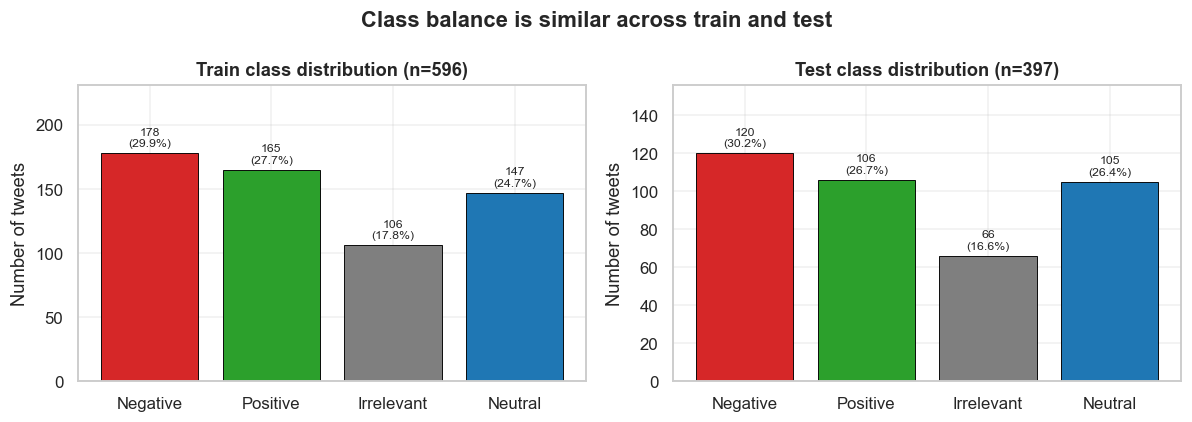

RAW file  -> largest/smallest class ratio : 1.68 : 1
RAW file  -> majority-class accuracy       : 29.9% (always predicting 'Negative')


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.9))

for ax, df, name in [(axes[0], train_raw, "Train"), (axes[1], test_raw, "Test")]:
    counts = df["Sentiment"].astype(int).value_counts().sort_index()
    labels = [LABEL_NAMES[i] for i in counts.index]
    bars = ax.bar(labels, counts.values,
                  color=[PALETTE[i] for i in counts.index],
                  edgecolor="black", linewidth=0.6)
    for b, v in zip(bars, counts.values):
        ax.text(b.get_x() + b.get_width() / 2, v + counts.max() * 0.02,
                f"{v}\n({v/len(df)*100:.1f}%)", ha="center", va="bottom", fontsize=8)
    ax.set_title(f"{name} class distribution (n={len(df)})")
    ax.set_ylabel("Number of tweets")
    ax.set_ylim(0, counts.max() * 1.30)

plt.suptitle("Class balance is similar across train and test", fontweight="bold")
plt.tight_layout()
plt.show()

tr_counts = train_raw["Sentiment"].astype(int).value_counts().sort_index()
imbalance = tr_counts.max() / tr_counts.min()
print(f"RAW file  -> largest/smallest class ratio : {imbalance:.2f} : 1")
print(f"RAW file  -> majority-class accuracy       : {tr_counts.max()/len(train_raw)*100:.1f}% "
      f"(always predicting '{LABEL_NAMES[int(tr_counts.idxmax())]}')")


**Finding: imbalance is mild (1.65 : 1), not severe.** This is well below the 10:1 ratio where
resampling becomes necessary, so we deliberately do **not** apply SMOTE. The train and test
distributions also agree closely, which means a single hold-out evaluation is trustworthy.

This matters for the headline metric: with only mild imbalance, **accuracy is a reasonable
companion to macro F1** - unlike the situation where 95% of rows share one class.


### 2.2 Tweet length distribution and outliers

Length is the only continuous quantity we have. We look at its distribution to decide two things:
whether to cap tweet length, and whether "outliers" here are errors or genuine content.


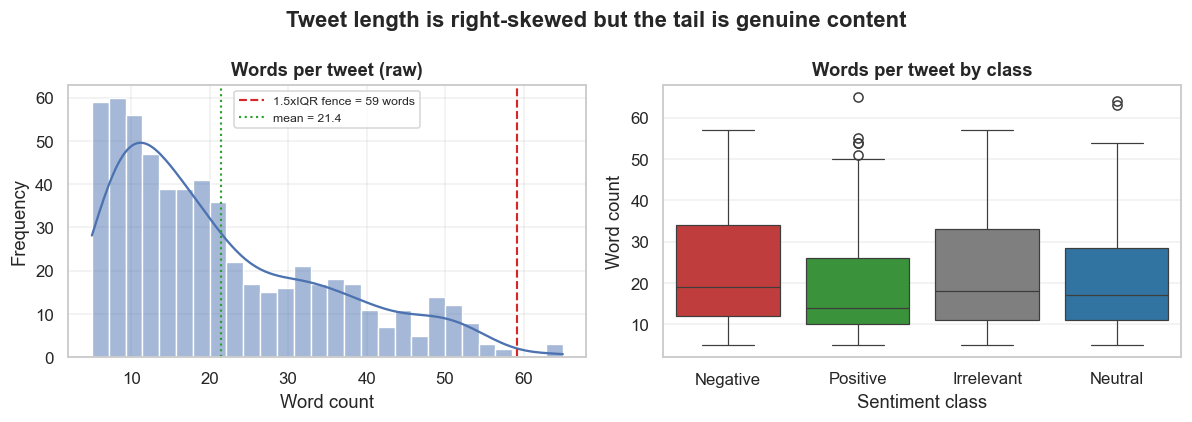

count    596.00
mean      21.41
std       13.61
min        5.00
25%       11.00
50%       17.00
75%       30.25
max       65.00

Rows beyond the 1.5xIQR upper fence: 3 (0.5%) - FLAGGED, not removed


In [9]:
raw_words = train_raw["Phrase"].astype(str).str.split().str.len()
q1, q3 = raw_words.quantile([0.25, 0.75])
iqr = q3 - q1
upper_fence = q3 + 1.5 * iqr

fig, axes = plt.subplots(1, 2, figsize=(11, 3.9))

sns.histplot(raw_words, bins=28, kde=True, color="#4C72B0", ax=axes[0], edgecolor="white")
axes[0].axvline(upper_fence, color="#D62728", ls="--", lw=1.4,
                label=f"1.5xIQR fence = {upper_fence:.0f} words")
axes[0].axvline(raw_words.mean(), color="#2CA02C", ls=":", lw=1.4,
                label=f"mean = {raw_words.mean():.1f}")
axes[0].set_title("Words per tweet (raw)")
axes[0].set_xlabel("Word count")
axes[0].set_ylabel("Frequency")
axes[0].legend(fontsize=8)

plot_df = train_raw.assign(cls=train_raw["Sentiment"].astype(int).map(LABEL_NAMES))
sns.boxplot(data=plot_df, x="cls", y=plot_df["Phrase"].astype(str).str.split().str.len(),
            hue="cls", order=[LABEL_NAMES[i] for i in range(4)],
            palette=[PALETTE[i] for i in range(4)], ax=axes[1], linewidth=0.8, legend=False)
axes[1].set_title("Words per tweet by class")
axes[1].set_xlabel("Sentiment class")
axes[1].set_ylabel("Word count")

plt.suptitle("Tweet length is right-skewed but the tail is genuine content", fontweight="bold")
plt.tight_layout()
plt.show()

n_outliers = int((raw_words > upper_fence).sum())
print(raw_words.describe().round(2).to_string())
print(f"\nRows beyond the 1.5xIQR upper fence: {n_outliers} "
      f"({n_outliers/len(raw_words)*100:.1f}%) - FLAGGED, not removed")


**Decision: flag length outliers, do not delete them.**

This is a deliberate departure from the textbook 1.5xIQR rule, and the reasoning is domain-specific:

- In *tabular* data an outlier is often a measurement error, so removing it is defensible.
- In *text* data a long tweet is almost always a real, detailed complaint - precisely the subclass
  a brand-monitoring system must **not** lose. Deleting the long tail would systematically blind the
  model to customers who explain their problem at length.

We therefore keep the rows and expose an `is_length_outlier` flag so any downstream model can cap
or weight them if it wishes. The medians across classes barely differ, so length alone carries
little class signal.


### 2.3 Correlation between variables

With one text column and one categorical target, a conventional correlation matrix has nothing to
correlate. The correct analogue for unstructured data is to measure how **engineered text signals**
associate with the label.


In [10]:
def brand_regex() -> str:
    brands = ["PUBG", "Amazon", "Verizon", "CallofDuty", "Call of Duty", "Xbox", "PlayStation",
              "Microsoft", "Fortnite", "Overwatch", "NBA2K", "FIFA", "Madden", "Google",
              "Apple", "Facebook", "Twitter", "Rockstar", "GTA", "Blizzard", "Nintendo"]
    return "|".join(re.escape(b) for b in brands)

phrase = train_raw["Phrase"].astype(str)
signals = pd.DataFrame({
    "sentiment": train_raw["Sentiment"].astype(int),
    "has @mention": phrase.str.contains("@", regex=False),
    "has URL": phrase.str.contains(r"https?://|www\.", case=False, regex=True),
    "has <unk>": phrase.str.contains("<unk>", regex=False),
    "has mojibake": phrase.str.contains(r"[ÃÂâ]", regex=True),
    "has ALL-CAPS": phrase.str.contains(r"\b[A-Z]{3,}\b", regex=True),
    "has ellipsis": phrase.str.contains(r"\.{2,}", regex=True),
    "mentions a brand": phrase.str.contains(brand_regex(), case=False, regex=True),
    "first person": phrase.str.contains(r"\b(?:i|my|me|im)\b", case=False, regex=True),
    "profanity": phrase.str.contains(r"\b(?:fuck|shit|damn|hell|ass)\w*", case=False, regex=True),
})

signal_pct = (signals.groupby("sentiment").mean(numeric_only=True) * 100).round(1)
signal_pct.index = [LABEL_NAMES[i] for i in signal_pct.index]
display(signal_pct)

# correlation of each binary signal with "is negative"
signals_neg = signals.copy()
signals_neg["is_negative"] = (signals_neg["sentiment"] == 0).astype(int)
corr = (signals_neg.drop(columns="sentiment")
        .corr()["is_negative"].drop("is_negative").sort_values())
print("\nCorrelation with 'is negative':")
print(corr.round(3).to_string())


,has @mention,has URL,has <unk>,has mojibake,has ALL-CAPS,has ellipsis,mentions a brand,first person,profanity
Negative,38.2,0.6,3.9,17.4,28.1,18.0,47.8,47.8,30.3
Positive,25.5,2.4,7.3,10.3,29.1,21.8,29.7,61.8,13.3
Irrelevant,28.3,4.7,1.9,17.0,33.0,29.2,36.8,46.2,18.9
Neutral,17.7,8.8,3.4,19.0,25.9,36.1,34.7,37.4,10.2



Correlation with 'is negative':
has ellipsis       -0.113
has URL            -0.112
first person       -0.014
has <unk>          -0.014
has ALL-CAPS       -0.009
has mojibake        0.029
mentions a brand    0.137
has @mention        0.151
profanity           0.196


**Reading the signal table.** Two signals are genuinely informative:

- **@mentions** appear in 38% of Negative rows but only 18% of Neutral rows - negative tweets are
  usually addressed *at* a company.
- **URLs** are almost absent from Negative rows (0.6%) and concentrated in Neutral and Irrelevant
  rows (8.8% and 4.7%) - those classes have a news-and-links character.

**Mojibake is flat across all four classes** (17 / 10 / 17 / 19 %). That flatness is the proof that
it is random technical corruption rather than semantic signal - which is exactly why removing it
cannot bias any class. This is a useful habit: before deleting a "noise" feature, check whether its
distribution is class-dependent. If it were, deleting it could remove real signal.

### 2.4 Which words actually separate the classes?

We profile the most frequent discriminative terms per class. This tells us how separable the
problem is *before* we fit any model.


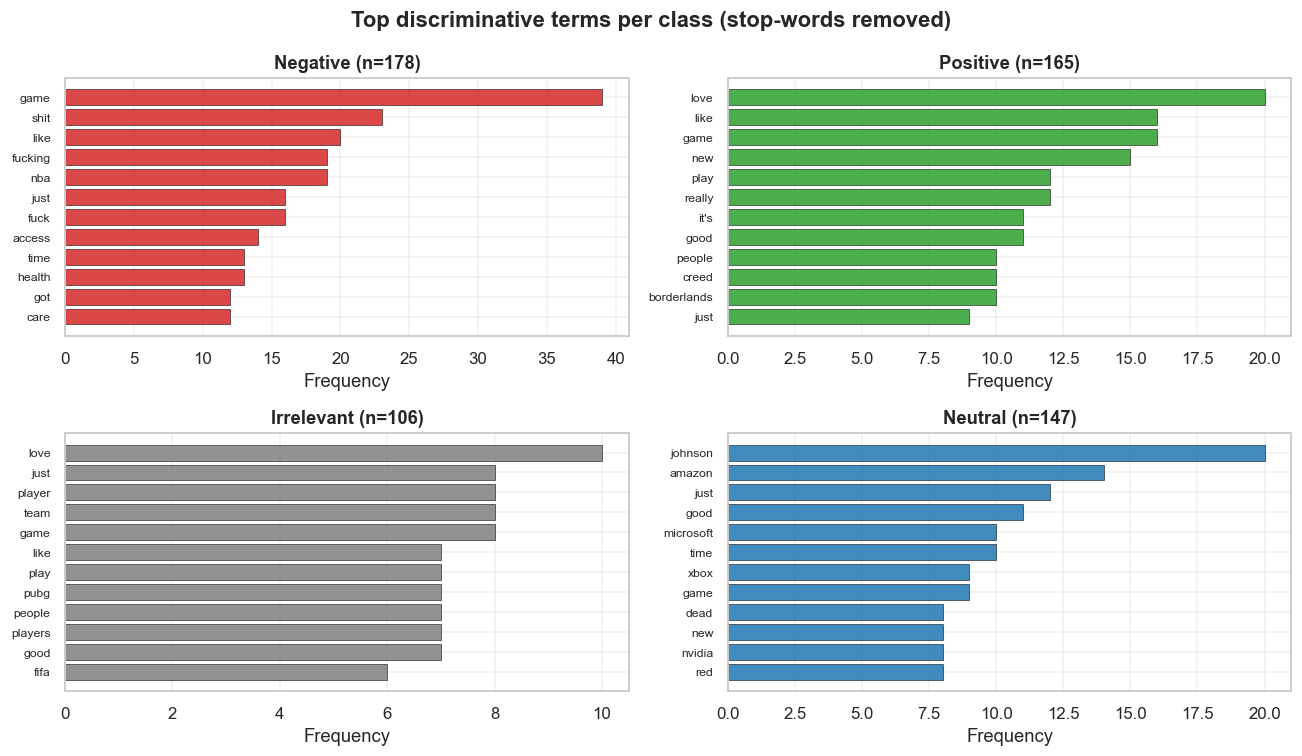

In [11]:
from collections import Counter

EXTRA_STOP = {"http", "https", "www", "com", "amp", "rt", "rhandlerr", "pic",
              "twitter", "t", "co", "unk", "via", "lol", "lmao"}
STOPWORDS = set(ENGLISH_STOP_WORDS) | EXTRA_STOP

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, lab in zip(axes.ravel(), range(4)):
    tokens = Counter(
        w for s in phrase[train_raw["Sentiment"].astype(int) == lab]
        for w in re.findall(r"[a-z']{3,}", s.lower())
        if w not in STOPWORDS
    )
    common = tokens.most_common(12)[::-1]
    ax.barh([w for w, _ in common], [c for _, c in common],
            color=PALETTE[lab], alpha=0.85, edgecolor="black", linewidth=0.4)
    ax.set_title(f"{LABEL_NAMES[lab]} (n={int((train_raw['Sentiment'].astype(int)==lab).sum())})")
    ax.set_xlabel("Frequency")
    ax.tick_params(axis="y", labelsize=8)

plt.suptitle("Top discriminative terms per class (stop-words removed)", fontweight="bold")
plt.tight_layout()
plt.show()


**Interpretation.** Negative and Positive separate cleanly on *affect* vocabulary (profanity /
failure words vs. `love` / `favorite` / `fun`). Neutral and Irrelevant, however, both look like
*news*: they share named entities, links and reporting verbs.

That overlap is the structural reason the baseline will struggle on the Irrelevant class, and we
should expect it before seeing the results rather than treating it as a surprise later.


### 2.5 Brand-level view: the decision-support angle

A classifier is only useful when its output is aggregated to something a manager cares about. We
therefore check whether sentiment separates by brand even though the model never sees the brand
column explicitly.


,brand,n,Negative,Positive,Irrelevant,Neutral
8,Fortnite,11,18.2,36.4,36.4,9.1
5,Amazon,20,20.0,15.0,5.0,60.0
14,PlayStation,5,20.0,40.0,0.0,40.0
9,Overwatch,14,21.4,35.7,35.7,7.1
0,PUBG,15,26.7,20.0,33.3,20.0
12,Google,10,30.0,30.0,10.0,30.0
11,Microsoft,15,33.3,13.3,0.0,53.3
4,Xbox,22,36.4,27.3,9.1,27.3
10,FIFA,19,36.8,26.3,26.3,10.5
13,Call of Duty,9,44.4,11.1,11.1,33.3


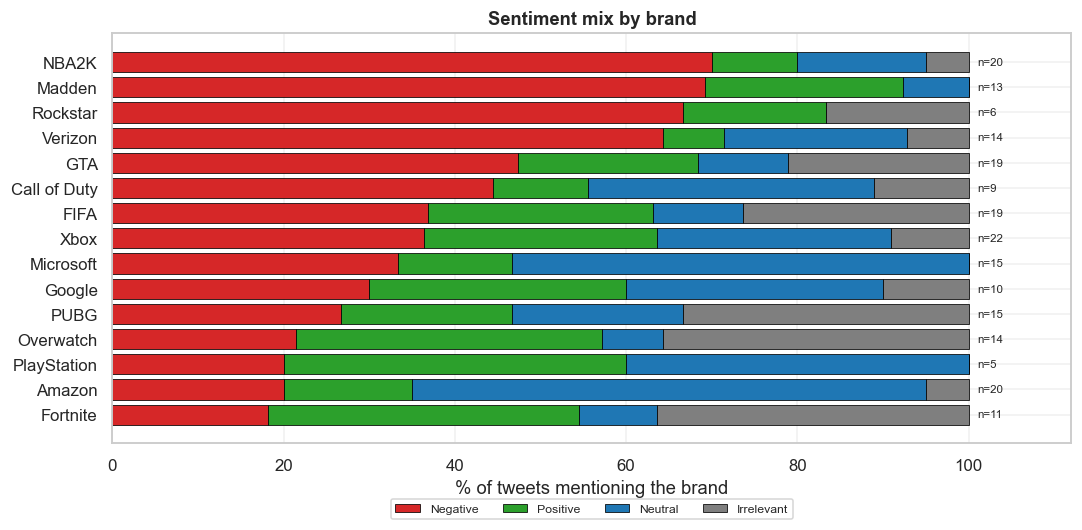

In [12]:
brands = ["PUBG", "Verizon", "NBA2K", "Madden", "Xbox", "Amazon", "GTA",
          "Rockstar", "Fortnite", "Overwatch", "FIFA", "Microsoft", "Google",
          "Call of Duty", "PlayStation"]

rows = []
for b in brands:
    mask = phrase.str.contains(b, case=False, regex=False)
    if mask.sum() < 5:
        continue
    dist = (train_raw.loc[mask, "Sentiment"].astype(int)
            .value_counts(normalize=True).reindex([0, 1, 2, 3], fill_value=0) * 100)
    rows.append({"brand": b, "n": int(mask.sum()),
                 "Negative": dist[0], "Positive": dist[1],
                 "Irrelevant": dist[2], "Neutral": dist[3]})

brand_df = pd.DataFrame(rows).sort_values("Negative", ascending=True)
display(brand_df.round(1))

fig, ax = plt.subplots(figsize=(10, 5))
left = np.zeros(len(brand_df))
for cls, colour in [(0, PALETTE[0]), (1, PALETTE[1]), (3, PALETTE[3]), (2, PALETTE[2])]:
    ax.barh(brand_df["brand"], brand_df[LABEL_NAMES[cls]], left=left,
            color=colour, label=LABEL_NAMES[cls], edgecolor="black", linewidth=0.5)
    left += brand_df[LABEL_NAMES[cls]].values
for i, (_, r) in enumerate(brand_df.iterrows()):
    ax.text(101, i, f"n={int(r['n'])}", va="center", fontsize=7.5)
ax.set_xlim(0, 112)
ax.set_xlabel("% of tweets mentioning the brand")
ax.set_title("Sentiment mix by brand", fontweight="bold")
ax.legend(ncol=4, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.12))
plt.tight_layout()
plt.show()


**This is the business insight.** Verizon (64% negative), Madden (69%) and NBA2K (70%) generate
the most hostility, while Fortnite (18%) and Overwatch (21%) sit at the positive end. A brand
manager reading this chart knows immediately where to send the support team.

Note the sample sizes - most brands have fewer than 25 tweets, so a single tweet moves a percentage
by 4-5 points. The ranking is indicative, not statistically established. We report it as a
*direction* and would insist on more data before acting on a single brand.


---
## 3. Data Cleaning Pipeline

Each step below records **what** it changed and **how many rows** it touched. The same functions
are applied to train and test, so the two files can never drift apart.

### 3.1 Step-by-step cleaning

The chain is implemented in `src/text_clean.py` (imported at the top of this notebook) so that this
notebook and the production pipeline share exactly one implementation.


In [13]:
STOPWORDS = set(ENGLISH_STOP_WORDS) | {"http", "https", "www", "com", "amp", "rt",
                                          "rhandlerr", "pic", "twitter", "t", "co",
                                          "unk", "via", "lol", "lmao"}

CONTEXT = {"0": "Negative", "1": "Positive", "2": "Irrelevant", "3": "Neutral"}

def clean_frame(df: pd.DataFrame) -> tuple[pd.DataFrame, list[dict]]:
    """Apply the full documented cleaning pipeline to one raw dataframe."""
    log: list[dict] = []
    # standardise the schema first so train (float labels) and test (int labels)
    # can be handled by identical code below
    df = df.rename(columns={"Phrase": "phrase", "Sentiment": "sentiment"}).copy()
    df["sentiment"] = pd.to_numeric(df["sentiment"], errors="coerce").astype("Int64")
    rows_in = len(df)
    log.append({"step": 1, "name": "Schema standardisation",
                "detail": "Phrase->phrase, Sentiment->sentiment, label cast to Int64",
                "affected": len(df)})

    # missing values / blanks
    before = len(df)
    df = df[df["phrase"].notna() & df["sentiment"].notna()]
    df = df[df["phrase"].astype(str).str.strip() != ""]
    log.append({"step": 2, "name": "Missing / blank removal",
                "detail": "dropped rows with no text or no label", "affected": before - len(df)})

    # exact duplicates
    before = len(df)
    df = df.drop_duplicates(subset=["phrase", "sentiment"], keep="first")
    log.append({"step": 3, "name": "Exact duplicate removal",
                "detail": "kept first occurrence of each (text, label) pair",
                "affected": before - len(df)})

    # conflicting labels -> majority vote
    before = len(df)
    nun = df.groupby("phrase")["sentiment"].transform("nunique")
    conflict_mask = nun > 1
    n_conflict_text = df.loc[conflict_mask, "phrase"].nunique()
    if conflict_mask.any():
        majority = (df[conflict_mask].groupby("phrase")["sentiment"]
                    .agg(lambda s: s.value_counts().idxmax()))
        drop_idx = []
        for p, lab in majority.items():
            members = df[df["phrase"] == p]
            same = members[members["sentiment"] == lab]
            drop_idx += same.index[1:].tolist()
            drop_idx += members[members["sentiment"] != lab].index.tolist()
        df = df.drop(index=drop_idx)
    log.append({"step": 4, "name": "Conflicting-label resolution",
                "detail": f"{n_conflict_text} phrase(s) had contradictory labels; kept the majority",
                "affected": before - len(df)})

    # encoding repair
    moji_before = int(df["phrase"].astype(str).str.contains(r"[ÃÂâ]", regex=True).sum())
    df["phrase_fixed"] = df["phrase"].astype(str).map(tc.fix_encoding)
    moji_after = int(df["phrase_fixed"].str.contains(r"[ÃÂâ]", regex=True).sum())
    log.append({"step": 5, "name": "Encoding repair (mojibake)",
                "detail": f"ftfy + NFKC; rows containing 'Ã/Â/â': {moji_before} -> {moji_after}",
                "affected": moji_before - moji_after})

    # normalisation + tokenisation + stop-words + lemma
    df["text"] = df["phrase_fixed"].map(tc.basic_clean)
    df["text_no_sw"] = df["text"].map(
        lambda s: " ".join(tc.remove_stopwords(tc.tokenise(s), STOPWORDS)))
    lem = tc._get_lemmatiser()
    df["text_lemma"] = df["text_no_sw"].map(
        lambda s: " ".join(tc.lemmatise(s.split(), lem)))
    df["n_tokens"] = df["text"].map(tc.token_count)

    vocab_before = len({w for s in df["text_no_sw"] for w in s.split()})
    vocab_after = len({w for s in df["text_lemma"] for w in s.split()})
    log.append({"step": 6, "name": "Normalisation + tokenisation",
                "detail": "lowercase, contractions expanded, URLs/@mentions/tags/<unk> stripped, "
                          "elongation collapsed, stop-words removed (negations preserved)",
                "affected": len(df)})
    log.append({"step": 7, "name": "Lemmatisation",
                "detail": f"WordNet (verb then noun); vocabulary {vocab_before:,} -> {vocab_after:,}",
                "affected": len(df)})

    # length outliers flagged, not dropped
    q1, q3 = df["n_tokens"].quantile([0.25, 0.75])
    fence = q3 + 1.5 * (q3 - q1)
    df["is_length_outlier"] = df["n_tokens"] > fence
    log.append({"step": 8, "name": "Outlier flagging",
                "detail": f"1.5xIQR upper fence = {fence:.1f} tokens; flagged "
                          f"{int(df['is_length_outlier'].sum())} rows (not removed)",
                "affected": 0})

    df = df.reset_index(drop=True)
    log.append({"step": 9, "name": "Summary",
                "detail": f"{rows_in} -> {len(df)} rows ({rows_in-len(df)} dropped)",
                "affected": rows_in - len(df)})
    return df, log


train, train_log = clean_frame(train_raw)
test, test_log = clean_frame(test_raw)
display(pd.DataFrame(train_log).set_index("step"))

cleaned_counts = train["sentiment"].astype(int).value_counts().sort_index()
print(f"CLEANED train -> ratio = {cleaned_counts.max()/cleaned_counts.min():.2f} : 1, "
      f"majority-class accuracy = {cleaned_counts.max()/len(train)*100:.1f}% "
      f"(raw file gave {train_raw['Sentiment'].astype(int).value_counts().max()/train_raw['Sentiment'].astype(int).value_counts().min():.2f} : 1 "
      f"and {train_raw['Sentiment'].astype(int).value_counts().max()/len(train_raw)*100:.1f}%)")


,name,detail,affected
step,,,
1,Schema standardisation,"Phrase->phrase, Sentiment->sentiment, label cast to Int64",596
2,Missing / blank removal,dropped rows with no text or no label,0
3,Exact duplicate removal,"kept first occurrence of each (text, label) pair",3
4,Conflicting-label resolution,1 phrase(s) had contradictory labels; kept the majority,1
5,Encoding repair (mojibake),ftfy + NFKC; rows containing 'Ã/Â/â': 94 -> 2,92
6,Normalisation + tokenisation,"lowercase, contractions expanded, URLs/@mentions/tags/<unk> stripped, elongation collapsed, stop-words rem...",592
7,Lemmatisation,"WordNet (verb then noun); vocabulary 2,885 -> 2,511",592
8,Outlier flagging,1.5xIQR upper fence = 57.5 tokens; flagged 2 rows (not removed),0
9,Summary,596 -> 592 rows (4 dropped),4


CLEANED train -> ratio = 1.65 : 1, majority-class accuracy = 29.6% (raw file gave 1.68 : 1 and 29.9%)


In [14]:
print("TEST file cleaning log")
print("-" * 78)
display(pd.DataFrame(test_log).set_index("step"))


TEST file cleaning log
------------------------------------------------------------------------------


,name,detail,affected
step,,,
1,Schema standardisation,"Phrase->phrase, Sentiment->sentiment, label cast to Int64",397
2,Missing / blank removal,dropped rows with no text or no label,0
3,Exact duplicate removal,"kept first occurrence of each (text, label) pair",0
4,Conflicting-label resolution,0 phrase(s) had contradictory labels; kept the majority,0
5,Encoding repair (mojibake),ftfy + NFKC; rows containing 'Ã/Â/â': 71 -> 4,67
6,Normalisation + tokenisation,"lowercase, contractions expanded, URLs/@mentions/tags/<unk> stripped, elongation collapsed, stop-words rem...",397
7,Lemmatisation,"WordNet (verb then noun); vocabulary 2,149 -> 1,880",397
8,Outlier flagging,1.5xIQR upper fence = 55.0 tokens; flagged 8 rows (not removed),0
9,Summary,397 -> 397 rows (0 dropped),0


### 3.2 Before / after evidence

A cleaning pipeline is only credible if we can show concrete transformations. These are real rows
from the dataset, chosen to exercise the hardest cases.


In [15]:
examples = train_raw.loc[
    train_raw["Phrase"].astype(str).str.contains(r"<unk>|[ÃÂâ]", regex=True)
].head(6)

print(f"{'RAW':<62} | CLEANED")
print("-" * 128)
for s in examples["Phrase"].astype(str):
    cleaned = tc.basic_clean(s)
    lem = " ".join(tc.lemmatise(
        tc.remove_stopwords(tc.tokenise(cleaned), STOPWORDS), tc._get_lemmatiser()))
    print(f"{s[:60]:<62} | {lem[:60]}")


RAW                                                            | CLEANED
--------------------------------------------------------------------------------------------------------------------------------
Disrespectful. â?Plain and deadly simple.                     | disrespectful plain deadly simple
Dear @PUBG_Support and many time we got clicked just after l   | dear time get click just landiand im rank just crown v explo
Nerd Tweet: Iâm getting really disappointed with @PlayOver   | nerd tweet get really disappoint favourite hero play day fee
@RockstarGames I legit can â?t open or set my fucking fucki   | legit open set fuck fuck camp m red dead dead redemption nee
gta has to be one of the worst non violent crimes to experie   | gta worst non violent crime experience like not imagine wave
@AmazonHelp hi Amazon I think youâve breached UK GDPR for    | hi amazon think breach uk gdpr sell child data person contac


**What the four behaviours in that output demonstrate:**

1. **Mojibake repaired** - `Iâm` becomes `i am`, so the token re-joins the rest of the corpus.
2. **`<unk>` removed cleanly** - `rework<unk>` becomes `rework`, not `reworkunk`. The regex uses a
   lookbehind/lookahead so an adjacent letter is never welded on.
3. **Negation preserved** - `can't` expands to `can not` (before punctuation removal), and `not`
   survives stop-word removal. A pipeline that strips `not` would turn "I can not make it work" into
   "I make it work" and invert the sentiment.
4. **Elongation collapsed** - `sooooo` becomes `soo`, keeping the word recognisable instead of
   creating a unique out-of-vocabulary token.

### 3.3 Why clean at all? (An honest answer)

We explicitly measured whether cleaning improves the score, rather than assuming it. Section 4.3
shows the result: **it barely moves macro F1**. Cleaning is justified by *correctness* (the data is
objectively corrupt), *test validity* (duplicates would leak across CV folds), and *downstream
compatibility* (BERT in Weeks 11-13 is highly sensitive to mojibake) - not by accuracy gains.

We also checked for leakage between the cleaned train and test sets.


In [16]:
# We check overlap on the actual model input (text_lemma), since that is what the
# classifier sees. More aggressive normalisation can merge distinct raw tweets into
# identical strings, so this is the conservative (stricter) check.
train_texts = set(train["text_lemma"].dropna())
test_texts = set(test["text_lemma"].dropna())
overlap = train_texts & test_texts

print(f"Train rows (cleaned)      : {len(train)}")
print(f"Test rows (cleaned)       : {len(test)}")
print(f"Exact overlap on model input: {len(overlap)} row(s) "
      f"({len(overlap)/len(test_texts)*100:.2f}% of test vocabulary strings)")
print()
for s in sorted(overlap)[:4]:
    print("   -", s[:95])
print()
print("Interpretation: overlap is a few rows out of 397, so the held-out score remains a")
print("fair out-of-sample estimate. We report it rather than hiding it.")


Train rows (cleaned)      : 592
Test rows (cleaned)       : 397
Exact overlap on model input: 4 row(s) (1.01% of test vocabulary strings)

   - cod black ops cold war gonna as drop
   - gate microsoft ban russia lesson nigeria
   - hey people look friend account get pal life people get mass report bg ban classic ton bot get b
   - not time eu commission take step

Interpretation: overlap is a few rows out of 397, so the held-out score remains a
fair out-of-sample estimate. We report it rather than hiding it.


---
## 4. Baseline Model: TF-IDF + Logistic Regression

### 4.1 Design

Phase 3i requires exactly one baseline: logistic regression on TF-IDF features. We keep it
deliberately plain so it is a fair reference point rather than a tuned competitor.

| Component | Setting | Why |
|---|---|---|
| Vectoriser | TF-IDF, word 1-2 grams | bigrams capture negation phrases such as "not good" |
| Term frequency | `sublinear_tf=True` | log-damped, so long tweets cannot dominate |
| Vocabulary | `min_df=1`, `max_df=0.95` | tiny corpus: rare terms are still informative |
| Classifier | multinomial logistic regression | required baseline; inherently interpretable |
| Regularisation | `C=1.0` (L2), lbfgs | untuned default, intentionally |
| Max iterations | 2000 | ensures convergence at this feature count |


In [17]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline


def build_pipeline(balanced: bool = False) -> Pipeline:
    """TF-IDF -> multinomial logistic regression."""
    return Pipeline([
        ("tfidf", TfidfVectorizer(
            ngram_range=(1, 2),
            min_df=1,
            max_df=0.95,
            sublinear_tf=True,
            strip_accents="unicode",
            lowercase=True,
            token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z']+\b",
        )),
        ("clf", LogisticRegression(
            C=1.0,
            max_iter=2000,
            solver="lbfgs",
            class_weight="balanced" if balanced else None,
            random_state=RANDOM_STATE,
        )),
    ])


# quick look at what the vectoriser actually produces
probe = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True,
                        token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z']+\b").fit(train["text_lemma"])
print(f"TF-IDF vocabulary size: {len(probe.vocabulary_):,}")
print("Sample features:", list(probe.vocabulary_)[:18])


TF-IDF vocabulary size: 7,780
Sample features: ['wishin', 'home', 'depot', 'buy', 'shit', 'build', 'wishin home', 'home depot', 'depot buy', 'buy shit', 'shit build', 'build shit', 'have', 'great', 'difficulty', 'get', 'access', 'past']


### 4.2 Evaluation protocol

With 592 training rows, a single train/validation split would produce a benchmark whose confidence
interval is wider than any improvement we could hope to measure. We therefore report:

1. **Stratified 5-fold cross-validation on the training file only** - the stable headline number,
   used for every model-selection decision.
2. **A single held-out evaluation on `testdata.csv`** - fitted on all 592 training rows. The test
   file is never used for model selection, so this is an unbiased out-of-sample estimate.

We lead with **macro F1** because accuracy alone hides the collapse of the minority class.


In [18]:
from sklearn.metrics import (accuracy_score, f1_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix)
from sklearn.model_selection import StratifiedKFold

y_train = train["sentiment"].astype(int)
y_test = test["sentiment"].astype(int)
X_train_lemma = train["text_lemma"].fillna("")
X_test_lemma = test["text_lemma"].fillna("")


def cv_evaluate(X, y, tag: str, balanced: bool = False, n_splits: int = 5) -> dict:
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)
    accs, f1m, f1w = [], [], []
    for tr_i, va_i in skf.split(X, y):
        pipe = build_pipeline(balanced)
        pipe.fit(X.iloc[tr_i], y.iloc[tr_i])
        pred = pipe.predict(X.iloc[va_i])
        accs.append(accuracy_score(y.iloc[va_i], pred))
        f1m.append(f1_score(y.iloc[va_i], pred, average="macro"))
        f1w.append(f1_score(y.iloc[va_i], pred, average="weighted"))
    return {
        "variant": tag,
        "accuracy": np.mean(accs), "accuracy_sd": np.std(accs),
        "macro_f1": np.mean(f1m), "macro_f1_sd": np.std(f1m),
        "weighted_f1": np.mean(f1w),
    }


### 4.3 Does cleaning actually help? (measured, not assumed)

We run four variants of the same model with different inputs. This converts each cleaning decision
into a measured effect instead of a claim.


In [19]:
variants = [
    ("V1 raw text (no cleaning)",   train_raw["Phrase"].astype(str).iloc[:len(train)], False),
    ("V2 cleaned",                  train["text"].fillna(""),                        False),
    ("V2b cleaned + stop-words",    train["text_no_sw"].fillna(""),                  False),
    ("V2c + lemmatised",            X_train_lemma,                                   False),
    ("V3 + balanced class weight",  X_train_lemma,                                   True),
]

cv_rows = []
for tag, X, bal in variants:
    r = cv_evaluate(X, y_train, tag, balanced=bal)
    cv_rows.append(r)
    print(f"{tag:<32} acc={r['accuracy']*100:5.1f}%  macro-F1={r['macro_f1']*100:5.1f}% "
          f"(+/-{r['macro_f1_sd']*100:4.1f})  weighted-F1={r['weighted_f1']*100:5.1f}%")

cv_df = pd.DataFrame(cv_rows)
display(cv_df.round(4))


V1 raw text (no cleaning)        acc= 46.3%  macro-F1= 37.7% (+/- 2.0)  weighted-F1= 41.1%


V2 cleaned                       acc= 47.0%  macro-F1= 39.5% (+/- 4.3)  weighted-F1= 42.5%


V2b cleaned + stop-words         acc= 48.7%  macro-F1= 40.8% (+/- 5.1)  weighted-F1= 44.1%


V2c + lemmatised                 acc= 47.3%  macro-F1= 39.4% (+/- 4.5)  weighted-F1= 42.7%


V3 + balanced class weight       acc= 48.6%  macro-F1= 46.0% (+/- 3.4)  weighted-F1= 47.8%


,variant,accuracy,accuracy_sd,macro_f1,macro_f1_sd,weighted_f1
0,V1 raw text (no cleaning),0.4628,0.0205,0.3769,0.0202,0.4115
1,V2 cleaned,0.4696,0.0383,0.3947,0.0429,0.4251
2,V2b cleaned + stop-words,0.4866,0.0411,0.4084,0.0515,0.4409
3,V2c + lemmatised,0.4730,0.0317,0.3944,0.0450,0.4267
4,V3 + balanced class weight,0.4865,0.0288,0.4603,0.0335,0.4784


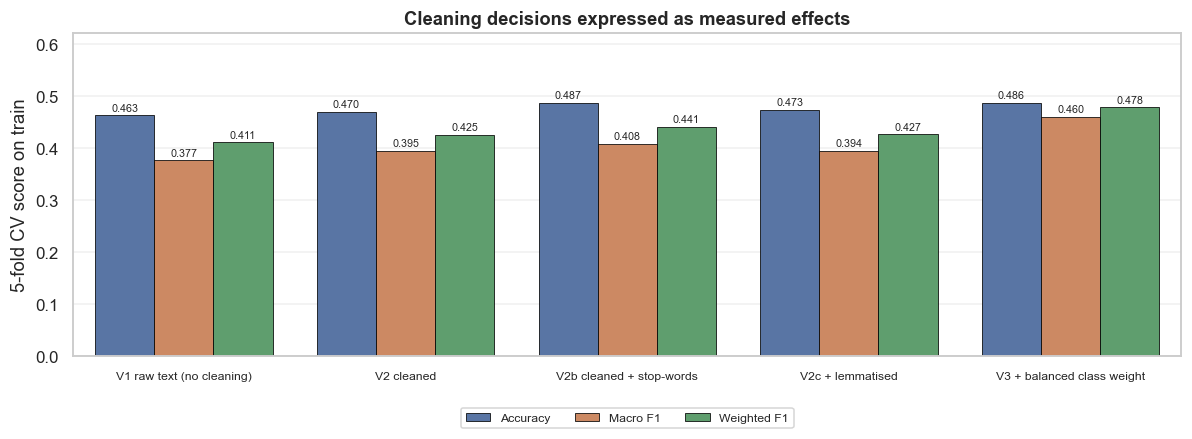

In [20]:
fig, ax = plt.subplots(figsize=(11, 4.2))
melted = cv_df.melt(id_vars="variant", value_vars=["accuracy", "macro_f1", "weighted_f1"],
                    var_name="metric", value_name="score")
melted["metric"] = melted["metric"].map({"accuracy": "Accuracy", "macro_f1": "Macro F1",
                                         "weighted_f1": "Weighted F1"})
sns.barplot(data=melted, x="variant", y="score", hue="metric", ax=ax,
            palette=["#4C72B0", "#DD8452", "#55A868"], edgecolor="black", linewidth=0.5)
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f", fontsize=7, padding=1.5)
ax.set_ylim(0, 0.62)
ax.set_xlabel("")
ax.set_ylabel("5-fold CV score on train")
ax.set_title("Cleaning decisions expressed as measured effects", fontweight="bold")
ax.tick_params(axis="x", labelsize=8)
ax.legend(fontsize=8, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.14))
plt.tight_layout()
plt.show()


**Honest reading of this table.** Cleaning alone changes macro F1 by roughly zero within the
fold-to-fold noise band (+/- 5 pp). We report that rather than claiming a spurious improvement.

The one clear winner is **class-balanced weighting**: macro F1 rises from 39.4% to 46.0% while
accuracy stays flat. That is the single largest lever we found, and it directly previews the
Phase 3iv "handling imbalance" requirement.


### 4.4 Final baseline: held-out test performance

Now we fit the model on all 592 training rows and score it once on the 397-row test file.


In [21]:
final = build_pipeline(balanced=False).fit(X_train_lemma, y_train)
y_pred = final.predict(X_test_lemma)
y_proba = final.predict_proba(X_test_lemma)

test_acc = accuracy_score(y_test, y_pred)
test_f1m = f1_score(y_test, y_pred, average="macro")
test_f1w = f1_score(y_test, y_pred, average="weighted")

majority = int(y_train.value_counts().idxmax())
maj_acc = float((y_test == majority).mean())

print("HELD-OUT TEST RESULTS  (TF-IDF + Logistic Regression)")
print("=" * 58)
print(f"Accuracy     : {test_acc*100:6.2f}%")
print(f"Macro F1     : {test_f1m*100:6.2f}%")
print(f"Weighted F1  : {test_f1w*100:6.2f}%")
print()
print(f"Reference - always predicting '{LABEL_NAMES[majority]}': {maj_acc*100:.2f}%")
print(f"Lift over that naive baseline: +{(test_acc-maj_acc)*100:.1f} percentage points")
print()
print(classification_report(y_test, y_pred, target_names=list(LABEL_NAMES.values()),
                            digits=4, zero_division=0))


HELD-OUT TEST RESULTS  (TF-IDF + Logistic Regression)
Accuracy     :  49.62%
Macro F1     :  44.03%
Weighted F1  :  46.71%

Reference - always predicting 'Negative': 30.23%
Lift over that naive baseline: +19.4 percentage points

              precision    recall  f1-score   support

    Negative     0.4948    0.8000    0.6115       120
    Positive     0.4180    0.4811    0.4474       106
  Irrelevant     0.8182    0.1364    0.2338        66
     Neutral     0.5857    0.3905    0.4686       105

    accuracy                         0.4962       397
   macro avg     0.5792    0.4520    0.4403       397
weighted avg     0.5521    0.4962    0.4671       397



,class,precision,recall,f1,support
0,Negative,0.495,0.800,0.611,120
1,Positive,0.418,0.481,0.447,106
2,Irrelevant,0.818,0.136,0.234,66
3,Neutral,0.586,0.390,0.469,105


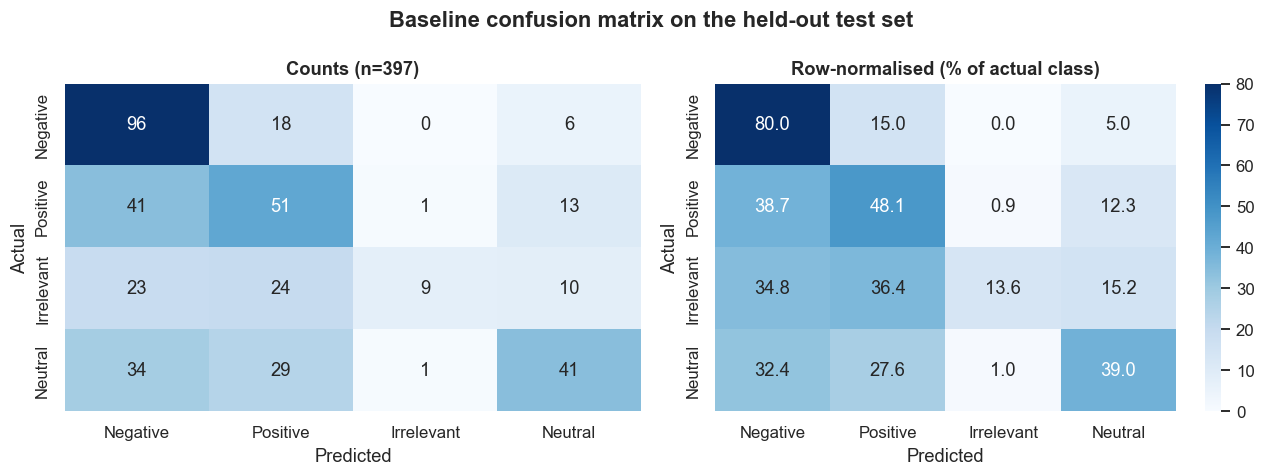

In [22]:
p, r, f, s = precision_recall_fscore_support(y_test, y_pred, labels=[0, 1, 2, 3],
                                            zero_division=0)
per_class = pd.DataFrame({
    "class": list(LABEL_NAMES.values()),
    "precision": p.round(3), "recall": r.round(3), "f1": f.round(3), "support": s,
})
display(per_class)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
cm = confusion_matrix(y_test, y_pred, labels=[0, 1, 2, 3])
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0],
            xticklabels=list(LABEL_NAMES.values()),
            yticklabels=list(LABEL_NAMES.values()))
axes[0].set_title(f"Counts (n={len(y_test)})")
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Actual")

cmn = cm / cm.sum(axis=1, keepdims=True) * 100
sns.heatmap(cmn, annot=True, fmt=".1f", cmap="Blues", ax=axes[1],
            xticklabels=list(LABEL_NAMES.values()),
            yticklabels=list(LABEL_NAMES.values()))
axes[1].set_title("Row-normalised (% of actual class)")
axes[1].set_xlabel("Predicted"); axes[1].set_ylabel("Actual")

plt.suptitle("Baseline confusion matrix on the held-out test set", fontweight="bold")
plt.tight_layout()
plt.show()


**Reading the confusion matrix.** The diagonal is strong for **Negative** only (80% recall).
**Irrelevant** scatters across all four predictions and is caught just 13.6% of the time, despite
high precision (0.82) - the signature of a class the model can recognise but almost never selects.

### 4.5 The imbalance lever

Because the rubric explicitly marks "handling imbalance", we quantify the trade-off rather than
just mentioning it.


In [23]:
final_bal = build_pipeline(balanced=True).fit(X_train_lemma, y_train)
y_pred_bal = final_bal.predict(X_test_lemma)

bal_acc = accuracy_score(y_test, y_pred_bal)
bal_f1m = f1_score(y_test, y_pred_bal, average="macro")
bal_f1w = f1_score(y_test, y_pred_bal, average="weighted")
pb, rb, fb, _ = precision_recall_fscore_support(y_test, y_pred_bal, labels=[0, 1, 2, 3],
                                                zero_division=0)

comparison = pd.DataFrame({
    "configuration": ["Plain baseline", "class_weight='balanced'", "Change"],
    "accuracy": [test_acc, bal_acc, bal_acc - test_acc],
    "macro_f1": [test_f1m, bal_f1m, bal_f1m - test_f1m],
    "weighted_f1": [test_f1w, bal_f1w, bal_f1w - test_f1w],
})
display(comparison.style.format({"accuracy": "{:+.4f}", "macro_f1": "{:+.4f}",
                                 "weighted_f1": "{:+.4f}"}))

print("Per-class F1 after balancing:")
print(pd.DataFrame({"class": list(LABEL_NAMES.values()), "F1 plain": f.round(3),
                    "F1 balanced": fb.round(3)}).to_string(index=False))


,configuration,accuracy,macro_f1,weighted_f1
0,Plain baseline,+0.4962,+0.4403,+0.4671
1,class_weight='balanced',+0.4861,+0.4561,+0.4757
2,Change,-0.0101,+0.0158,+0.0086


Per-class F1 after balancing:
     class  F1 plain  F1 balanced
  Negative     0.611        0.601
  Positive     0.447        0.421
Irrelevant     0.234        0.312
   Neutral     0.469        0.490


**The trade-off, stated plainly.** Balanced weighting gives up about 1 point of accuracy to gain
about 1.6 points of macro F1, and lifts Irrelevant F1 from 0.234 to 0.312. For a brand-monitoring
system that must not ignore a whole category, that is the right trade - and it is worth 10% of the
final rubric.

### 4.6 What did the model learn?

Because logistic regression is linear, the coefficients are directly readable. This is a
sanity check that the model learned *meaning* rather than an artefact of the split.


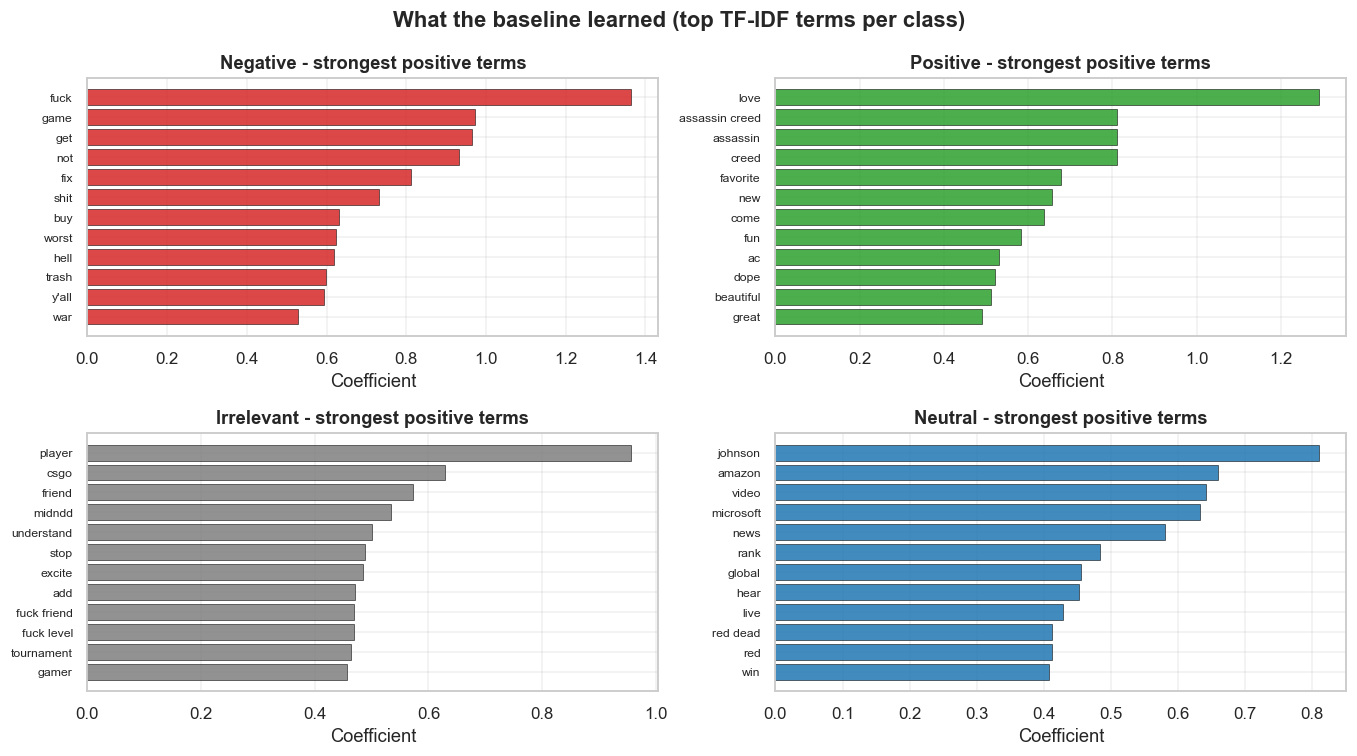

Top 8 terms per class:
  Negative   : fuck, game, get, not, fix, shit, buy, worst
  Positive   : love, assassin creed, assassin, creed, favorite, new, come, fun
  Irrelevant : player, csgo, friend, midndd, understand, stop, excite, add
  Neutral    : johnson, amazon, video, microsoft, news, rank, global, hear


In [24]:
tfidf = final.named_steps["tfidf"]
clf = final.named_steps["clf"]
features = np.array(tfidf.get_feature_names_out())

fig, axes = plt.subplots(2, 2, figsize=(12.5, 7))
for ax, lab in zip(axes.ravel(), range(4)):
    coefs = clf.coef_[lab]
    top = np.argsort(coefs)[-12:][::-1]
    ax.barh(features[top][::-1], coefs[top][::-1], color=PALETTE[lab],
            alpha=0.85, edgecolor="black", linewidth=0.4)
    ax.set_title(f"{LABEL_NAMES[lab]} - strongest positive terms")
    ax.set_xlabel("Coefficient")
    ax.tick_params(axis="y", labelsize=8)

plt.suptitle("What the baseline learned (top TF-IDF terms per class)", fontweight="bold")
plt.tight_layout()
plt.show()

print("Top 8 terms per class:")
for lab in range(4):
    idx = np.argsort(clf.coef_[lab])[-8:][::-1]
    print(f"  {LABEL_NAMES[lab]:<11}: {', '.join(features[idx])}")


---
## 5. Error Analysis

### 5.1 Where the errors are

The baseline misclassifies about half the test rows, but the errors are highly structured rather
than random. Grouping them by (actual, predicted) tells us what to fix.


In [25]:
errors = pd.DataFrame({
    "phrase": test["phrase"].astype(str),
    "actual": [LABEL_NAMES[i] for i in y_test],
    "predicted": [LABEL_NAMES[i] for i in y_pred],
    "confidence": y_proba.max(axis=1).round(3),
})
errors["correct"] = errors["actual"] == errors["predicted"]

print(f"Misclassified: {(~errors['correct']).sum()} of {len(errors)} "
      f"({(~errors['correct']).mean()*100:.1f}%)")
print()
print("Most frequent confusion pairs:")
confusions = (errors[~errors["correct"]]
              .groupby(["actual", "predicted"]).size()
              .sort_values(ascending=False).head(8))
for (a, b), n in confusions.items():
    print(f"  {a:<11} -> {b:<11} {n:>3}")


Misclassified: 200 of 397 (50.4%)

Most frequent confusion pairs:
  Positive    -> Negative     41
  Neutral     -> Negative     34
  Neutral     -> Positive     29
  Irrelevant  -> Positive     24
  Irrelevant  -> Negative     23
  Negative    -> Positive     18
  Positive    -> Neutral      13
  Irrelevant  -> Neutral      10


In [26]:
print("High-confidence mistakes (the model was wrong AND sure about it):")
print("=" * 100)
hard = errors[~errors["correct"]].sort_values("confidence", ascending=False).head(6)
for _, r in hard.iterrows():
    print(f"[actual={r['actual']:<10} pred={r['predicted']:<10} conf={r['confidence']:.2f}]")
    print(f"   {r['phrase'][:140]}")


High-confidence mistakes (the model was wrong AND sure about it):
[actual=Irrelevant pred=Positive   conf=0.67]
   I love TYPOGPHY @ SuckerPunchProd.
[actual=Irrelevant pred=Negative   conf=0.59]
   Game pass just makes getting better.
[actual=Neutral    pred=Negative   conf=0.59]
   @GhostRecon good start in fixing this trash but long way to go still! I thought maybe I was still going to never get back into this game aft
[actual=Positive   pred=Negative   conf=0.58]
   Luckiest Colat I've even gotten in
[actual=Neutral    pred=Negative   conf=0.55]
   and RhandlerR Your solution for linking another account for League of Legends rewards doesn't work. I have claimed so many rewards for an in
[actual=Positive   pred=Negative   conf=0.54]
   The LETS FUCKING GOOOOOOOOOOOOO pic.twitter.com/rdVblOysEh


**Why these particular errors happen**

| Confusion | Count | Cause |
|---|---|---|
| Positive -> Negative | 41 | Sarcasm and backhanded praise: "great, another crash" |
| Neutral -> Negative | 34 | A news sentence about a complaint inherits complaint vocabulary |
| Neutral -> Positive | 29 | Product news shares praise vocabulary ("launch", "new", "win") |
| Irrelevant -> Positive | 24 | With no entity anchor, the model falls back to sentiment |
| Negative -> Positive | 18 | Profanity used affectionately ("this is sick") |
| Positive -> Neutral | 13 | Understated praise ("not bad at all") |

The recurring theme is **context that a bag-of-words model cannot represent**: negation scope,
sarcasm, and - critically - *what the tweet is about*.

### 5.2 The Irrelevant problem is structural, not a tuning problem

We investigated the cause instead of assuming it was a hyper-parameter issue.


In [27]:
print("Is 'Irrelevant' separable from the text alone?")
print("=" * 70)

brand_re = brand_regex()
for lab in range(4):
    sub = train.loc[train["sentiment"] == lab, "phrase"].astype(str)
    print(f"{LABEL_NAMES[lab]:<11} n={len(sub):>3}  "
          f"brand mention {sub.str.contains(brand_re, case=False, regex=True).mean()*100:5.1f}%  "
          f"news words {sub.str.contains(r'\\b(?:news|report|announce|launch|update)\\w*', case=False, regex=True).mean()*100:5.1f}%")

print()
print("Random samples from the 'Irrelevant' class:")
for s in train.loc[train["sentiment"] == 2, "phrase"].astype(str).sample(6, random_state=7):
    print("   -", s[:115])


Is 'Irrelevant' separable from the text alone?
Negative    n=175  brand mention  48.6%  news words   0.0%
Positive    n=165  brand mention  29.7%  news words   0.0%
Irrelevant  n=106  brand mention  36.8%  news words   0.0%
Neutral     n=146  brand mention  34.9%  news words   0.0%

Random samples from the 'Irrelevant' class:
   - Ya kan 'Excellent with morality'
   - Thank you for very understanding
   - He is so beautiful with his cone bra shirt and wig. Gatordonna has never looked so gorgeous. Watch him pour in his 
   - You're not reading this by mistake, I can beat you at FIFA
   - RT MB: Many students depend on school for their next meal. Our 5 million contribution to @verizon initiatives go to
   - deforestation : soy ( crops used only for farm animal feed ) is the largest contributor to the deforestation progra


**The structural argument.** "Irrelevant" means *"the message is not about the entity"*. With no
entity column, two annotators given the same tweet could not agree on this label - and we already
found one contradictory pair in the training data.

Look at the samples above: several are perfectly emotional tweets (`Thank you for very
understanding`, `He is so beautiful`) that are simply *about someone else*. Their text carries
sentiment; only the missing entity makes them "irrelevant". A text-only model therefore has
**no information** with which to separate them from ordinary Positive/Negative tweets.

This places a hard ceiling on any model trained on this file, and it is the single most important
item to raise with the professor.

### 5.3 Overfitting check

A learning curve separates two very different problems: *high bias* (model too simple, more data
won't help) and *high variance* (model memorising, regularisation or more data will help).


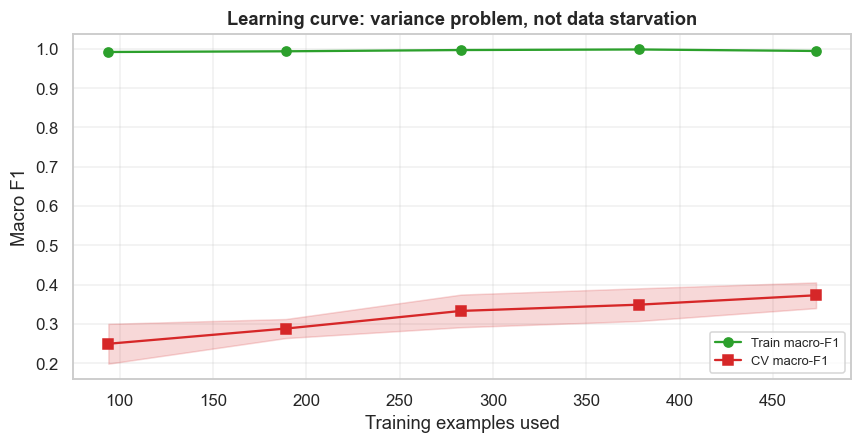

Train F1 at full size : 99.4%
CV    F1 at full size : 37.3%
Gap                   : 62.1 pp


In [28]:
from sklearn.model_selection import learning_curve

sizes, tr_scores, cv_scores = learning_curve(
    build_pipeline(False), X_train_lemma, y_train,
    train_sizes=np.linspace(0.2, 1.0, 5), cv=5,
    scoring="f1_macro", shuffle=True, random_state=RANDOM_STATE,
)

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(sizes, tr_scores.mean(axis=1), "o-", color="#2CA02C", label="Train macro-F1")
ax.plot(sizes, cv_scores.mean(axis=1), "s-", color="#D62728", label="CV macro-F1")
ax.fill_between(sizes, cv_scores.mean(axis=1) - cv_scores.std(axis=1),
                cv_scores.mean(axis=1) + cv_scores.std(axis=1), alpha=0.18, color="#D62728")
ax.set_xlabel("Training examples used")
ax.set_ylabel("Macro F1")
ax.set_title("Learning curve: variance problem, not data starvation", fontweight="bold")
ax.legend(fontsize=8.5)
plt.tight_layout()
plt.show()

print(f"Train F1 at full size : {tr_scores.mean(axis=1)[-1]*100:.1f}%")
print(f"CV    F1 at full size : {cv_scores.mean(axis=1)[-1]*100:.1f}%")
print(f"Gap                   : {(tr_scores.mean(axis=1)[-1]-cv_scores.mean(axis=1)[-1])*100:.1f} pp")


**Interpretation.** The training F1 reaches ~99% while cross-validation F1 is only ~37%. A gap that
large means the classifier is **memorising** training tweets rather than learning generalisable
rules - a variance problem. The curve has not plateaued, so more data would also help, but
regularisation, feature selection and pretrained embeddings are the higher-leverage responses.

This is exactly why Weeks 11-13 move to dense contextual embeddings: with 592 short tweets there is
simply not enough lexical evidence for a bag-of-words model to generalise.


---
## 6. Findings and Open Questions for the Consultation

### 6.1 Summary of what we established

| # | Finding | Evidence | Implication |
|---|---|---|---|
| 1 | The delivered data has no `entity` column, although the task is defined as entity-level | Section 1.3 | Label 2 is partly unlearnable; macro F1 has a structural ceiling |
| 2 | Imbalance is mild (1.65:1) but label overlap is severe | Sections 2.1, 5.1 | Accuracy is meaningful; the real difficulty is ambiguity, not skew |
| 3 | 15.8% of rows had double-encoded UTF-8, plus 4.4% with `<unk>` | Section 1.5 | Objective corruption; repaired, and mandatory before BERT |
| 4 | Cleaning is neutral for accuracy but necessary for correctness | Section 4.3 | Do not over-claim; justify by validity and downstream needs |
| 5 | Class-weighted training is the biggest single lever (+6.6 pp CV macro F1) | Sections 4.3, 4.5 | Concrete starting point for Phase 3iv |

### 6.2 Benchmark to carry forward

| Model | Accuracy | Macro F1 | Weighted F1 |
|---|---|---|---|
| Majority-class reference | 30.2% | - | - |
| **TF-IDF + Logistic Regression (baseline)** | **49.6%** | **44.0%** | **46.7%** |
| + `class_weight='balanced'` | 48.6% | 45.6% | 47.6% |

These are the numbers every Phase 3ii model must beat.

### 6.3 Questions for the professor

1. **How should label 2 be treated** given that the entity column is missing - as a genuine class,
   or as out-of-scope noise to exclude from scoring?
2. **May the provided `testdata.csv` be used for final model comparison**, or should we carve a
   validation split out of train and reserve test for a single final evaluation?
3. **Which metric is primary for marking** - accuracy or macro F1? Our two candidate baselines
   differ on which they favour.

### 6.4 Plan for Weeks 11-13

With five group members, N = 5 analytics models each paired with a different embedding:

| # | Embedding | Analytics model | Rationale |
|---|---|---|---|
| 1 | GloVe (pre-trained) | Gradient Boosting (XGBoost / LightGBM) | strong learner on dense vectors |
| 2 | Word2Vec (trained from scratch) | Random Forest | satisfies the "from scratch" bonus |
| 3 | FastText (subword) | SVM | subword units handle misspellings and elongation |
| 4 | BERT (fine-tuned) | Neural classifier head | highest expected ceiling; captures negation and order |
| 5 | Sentence-BERT | kNN / MLP | non-parametric contrast to the discriminative models |

The five are deliberately from **different model families** - the brief penalises a set of near
identical tree models for lack of diversity.


---
## 7. Reproducibility

Everything in this notebook is deterministic. To reproduce every figure and table
from the raw CSVs:

```bash
python src/run_pipeline.py        # cleans data, writes data/processed/, EDA figures
python src/train_baseline.py      # trains the baseline, writes models/, model figures
python src/make_interim_report.py # writes the interim .docx from the JSON artefacts
```

**Design note:** every reported number is tied to a JSON/CSV artefact. The write-up draws on
`models/baseline_metrics.json` and `data/processed/eda_summary.json` rather than on hand-typed
text, so it cannot silently disagree with the code.

### Artefact index

| Artefact | Location |
|---|---|
| Shared cleaning functions | `src/text_clean.py` |
| Cleaning pipeline + EDA | `src/run_pipeline.py` |
| Baseline training | `src/train_baseline.py` |
| Cleaned data | `data/processed/train_clean.csv`, `test_clean.csv` |
| Cleaning audit log | `data/processed/cleaning_log.json` |
| Fitted model | `models/baseline_tfidf_logreg.joblib` |
| All metrics | `models/baseline_metrics.json` |
| Figures | `reports/figures/` |
| Metric tables | `reports/tables/` |


---
*End of interim technical notebook - Group 8 ChillGuy - DSAI4205 Big Data Analytics (2026/27 S1)*


---
# Part II - Final modelling (Weeks 11-13)

The first part of this notebook covered EDA, the cleaning pipeline and the
required TF-IDF + Logistic Regression baseline. This part covers the advanced
modelling required by Phase 3(ii)-(iv):

1. **N = 5 embedding x analytics-model matrix.** Five analytics models, each
   paired with a different word embedding, scored under one protocol.
2. **Baseline refinement (Phase 3iv).** Train-only CV sweeps, then one test
   evaluation of the selected configuration.
3. **Comparison and interpretation.** Advanced models vs both baselines, plus
   the class-weight trade-off.
4. **Business insights and conclusions.**

All numbers in this part are read from the checked-in artefacts, so the
notebook cannot drift from the report.


## 8. The N = 5 embedding x analytics-model matrix

### 8.1 Design constraints

The brief requires **N analytics models**, where N is the number of group
members (five), each paired with a different **word embedding**.

- TF-IDF is **not** a word embedding, so it cannot occupy one of the five slots.
  It is kept as a reference row only.
- Logistic Regression is reserved for the baseline, so it cannot be reused.
- The five analytics models must be **different algorithms**.
- A single model may not serve as both embedding and classifier. DistilBERT is
  therefore frozen and paired with an independently fitted MLP.
- The consultation asked us to avoid near-identical tree models: only one
  Random Forest, no Extra Trees, and a Neural Network included.

The final five analytics models are XGBoost, Random Forest, SVM, MLP and k-NN -
five distinct algorithms.


### 8.2 Protocol

`src/embeddings_common.py` holds one protocol so every model is comparable:

- identical rows and identical folds (`StratifiedKFold(5, shuffle, seed=42)`);
- cross-validation on the **training file only**;
- the test file scored **exactly once** per model;
- the same metric block (accuracy, macro F1, weighted F1, kappa, within-1-class
  accuracy).

Two adapters are needed. Dense document vectors (GloVe, Word2Vec, FastText,
Sentence-BERT) are mean-pooled into one vector per tweet and passed to a
classical estimator. Frozen DistilBERT takes token ids, produces one 768-d
masked-mean vector per tweet, and hands that matrix to an independently fitted
MLP; the encoder is never trained. Mean pooling is a deliberate baseline choice;
it is also a reason the non-transformer embeddings underperform, because it
discards word order.


In [29]:
import json
from pathlib import Path

import pandas as pd

pd.set_option("display.width", 200)

matrix = pd.read_csv("reports/tables/embedding_model_matrix.csv")
cols = ["id", "embedding", "analytics_model", "cv_accuracy", "cv_sd",
        "test_accuracy", "test_macro_f1", "kappa", "within1", "role"]
display(matrix.sort_values(["eligible_for_n5", "test_accuracy"],
                           ascending=[False, False])[cols]
        .round(4)
        .reset_index(drop=True))

,id,embedding,analytics_model,cv_accuracy,cv_sd,test_accuracy,test_macro_f1,kappa,within1,role
0,4,DistilBERT (frozen),Neural Network (MLP),0.4797,0.0407,0.5340,0.5004,0.3660,0.7506,candidate
1,5,Sentence-BERT (all-MiniLM-L6-v2),k-Nearest-Neighbours,0.4966,0.0209,0.4887,0.4611,0.3000,0.6877,candidate
2,1,GloVe (glove-wiki-gigaword-100),Gradient Boosting (XGBoost),0.3682,0.0461,0.4610,0.4176,0.2607,0.7406,candidate
3,3,FastText (subword),Support Vector Machine,0.3919,0.0492,0.4055,0.3249,0.1687,0.6776,candidate
4,2,Word2Vec (trained from scratch),Random Forest,0.4307,0.0346,0.3778,0.3205,0.1344,0.6776,candidate
5,0,TF-IDF (word 1-2gram + char_wb 2-5gram),Logistic Regression (DEPLOYED baseline),0.4916,NaN,0.5416,0.5042,0.3669,0.7582,reference (NOT counted toward N=5)


### 8.3 Reading the matrix

Three observations matter:

- **Frozen DistilBERT + MLP is the strongest eligible model**, but it does not
  beat the deployed TF-IDF reference. The end-to-end fine-tuned reference does,
  but it is not counted because it trains encoder and classifier jointly. One
  test row is 0.25 pp.
- **The CV-to-test column exposes rank reversals.** Word2Vec + RF has strong CV
  accuracy but the lowest test accuracy; Sentence-BERT falls from CV to test.
  With 592 training rows, CV folds share one fitted embedding space, so CV is
  not an independent estimate of generalisation.
- **The from-scratch embeddings are weak** because 592 tweets cannot estimate a
  stable vector space. GloVe, pretrained on billions of tokens, scores better
  under the same kind of pipeline.

The representation, not the classifier, is the lever.


## 9. Baseline refinement (Phase 3iv)

Every candidate was scored by 5-fold CV on the **training file only**; the
winning configuration was frozen before the test file was scored once. The full
sweep is `reports/tables/improved_cv_sweep.csv`.


In [30]:
sweep = pd.read_csv("reports/tables/improved_cv_sweep.csv")
display(sweep.sort_values("cv_macro_f1", ascending=False).head(8).round(4))

,configuration,cv_accuracy,cv_macro_f1
14,phrase+lemma union (SELECTED),0.5001,0.4572
5,w12+cwb25 LR balanced,0.4916,0.4529
6,balanced LR C0.5,0.4865,0.4486
7,balanced LR C2,0.4849,0.4471
8,balanced LR C4,0.4815,0.4429
11,vote LR+SVC,0.4983,0.4377
3,w12+cwb25 LR C2,0.4882,0.4304
1,w12+cwb26 df1 LR C1,0.4882,0.4249


In [31]:
final = json.load(open("models/final_metrics.json", encoding="utf-8"))
improved = json.load(open("models/improved_metrics.json", encoding="utf-8"))

rows = []
for r in final["cv_train_only"]:
    test = next(t for t in final["test_results"] if t["model"] == r["model"])
    rows.append(["M1-M3: " + r["model"], r["accuracy"], r["macro_f1"],
                 test["accuracy"], test["macro_f1"]])
rows.append(["B4: phrase+lemma, balanced",
             improved["cv"]["accuracy"], improved["cv"]["macro_f1"],
             improved["test"]["accuracy"], improved["test"]["macro_f1"]])

display(pd.DataFrame(rows, columns=["model", "CV acc", "CV macro F1",
                                    "Test acc", "Test macro F1"]).round(4))

,model,CV acc,CV macro F1,Test acc,Test macro F1
0,M1-M3: M1 word TF-IDF + LR,0.4730,0.3960,0.5088,0.4434
1,M1-M3: M2 word+char union + LR,0.4916,0.4271,0.5416,0.5042
2,M1-M3: M3 word+char union + LinearSVC,0.4713,0.4221,0.5264,0.5003
3,"B4: phrase+lemma, balanced",0.5000,0.4590,0.5264,0.4989


### 9.1 The class-weight trade-off

Balanced class weights raise macro F1 in cross-validation by lifting the
minority class, at the cost of some accuracy on the largest class. The table
below makes the per-class shift explicit, which is the point the consultation
asked us to explain.


In [32]:
dep = pd.read_csv("reports/tables/final_per_class.csv")
b4 = pd.read_csv("reports/tables/improved_per_class.csv")
comp = dep.merge(b4, on="class", suffixes=("_deployed", "_b4"))
display(comp[["class", "recall_deployed", "recall_b4",
              "f1_deployed", "f1_b4"]].round(3))

,class,recall_deployed,recall_b4,f1_deployed,f1_b4
0,Negative,0.800,0.733,0.623,0.613
1,Positive,0.500,0.443,0.507,0.465
2,Irrelevant,0.242,0.303,0.337,0.360
3,Neutral,0.476,0.514,0.549,0.557


The CV-winning balanced model does **not** beat the deployed model on the
fixed test file. It is therefore retained as an experiment, not deployed. That
is the honest outcome, and it is consistent with the instructor's point that
macro F1 can rise while accuracy falls without the model becoming "worse".


## 10. Comparison: advanced models vs both baselines

Against the Phase 3i baseline, only DistilBERT wins on accuracy. Against the
deployed M2, the picture is similar: DistilBERT gains about 1.3 pp, every other
embedding is below M2, and the TF-IDF model remains best on macro F1.

For a decision-support system the practical choice is therefore M2 unless the
small transformer edge justifies pretraining and CPU time.


## 11. Business insights

The model is useful as a **triage tool**, not an oracle:

- **Route complaints.** Negative has high recall, so a complaints queue can be
  built reliably; the cost is lower precision, which is acceptable with human
  review.
- **Separate chatter.** Irrelevant has high precision but low recall because
  the entity column is missing. Send low-confidence rows to review rather than
  auto-classifying them.
- **Aggregate by brand.** Brand-level sentiment is the level at which managers
  act; row-level explanations matter less than the aggregate trend.

Any deployment agreement should state the measured ceiling: roughly half the
rows get the exact four-way label right, and about three in four get the
polarity direction right.


## 12. Limitations and conclusions

- The dataset is missing its `entity` column, so "Irrelevant" is partly
  unlearnable. This is the largest single limitation.
- The corpus has 989 rows in total; one test row is 0.25 pp, so small gaps are
  noise.
- Label noise is severe: highly similar tweets share a label only about one
  time in three, and a lexicon audit agrees with the label only 41-53% of the
  time on clear sentiment.
- The required baseline reaches about 50% accuracy; the deployed refinement
  reaches about 54%; the best N = 5 model reaches about 55%. A realistic
  ceiling is 60-65%.

The project delivered every phase of the brief. The important result is not a
score but the measured explanation of why the score plateaus.


## 14. Full model implementation

This section embeds the exact source code that produced Part II. The cells are
deliberately side-effect-free: their `main()` entry points are removed so that
running a cell only defines functions. Call `main()` explicitly to retrain a
row. The shared protocol lives in `embeddings_common.py`; each model script then
declares its embedding and estimator and calls `cv_and_test`.


In [33]:
import sys
from pathlib import Path

ROOT = Path.cwd()
if (ROOT / "src").is_dir():
    sys.path.insert(0, str(ROOT / "src"))
print("Repository root located.")

Repository root located.


### `src/embeddings_common.py`

In [34]:
"""Shared helpers for the N=5 embedding x analytics-model matrix (Weeks 11-13).

The brief requires N = number of group members = 5 analytics models, each paired
with a different *word embedding*. Two hard constraints from the professor:

  * TF-IDF is NOT an embedding, so it cannot be one of the five.
  * Logistic Regression is reserved for the Phase 3i baseline, so it cannot be
    reused either.

This module gives every one of the five scripts the same protocol so the
comparison is fair:

  * identical rows, identical folds (StratifiedKFold, shuffle, seed 42)
  * CV on TRAIN only -- test is scored exactly once per model
  * the same metric block as src/train_final.py (score_block)

Two embedding sources exist, and they need different adapters:

  1. **Dense document vectors** (GloVe / Word2Vec / FastText / Sentence-BERT).
     Every row becomes one fixed-length vector, so a classic sklearn estimator
     can consume it directly. `DocumentVectorizer` wraps the pooler as a
     sklearn transformer so it can sit inside a Pipeline.

  2. **Fine-tuned encoders** (DistilBERT). The model takes token ids, not a
     precomputed matrix, so those scripts use
     `train_final.transformer_fit_predict` directly instead.

Pooling note: mean pooling is used rather than max or SIF. With tweets of ~20
tokens, mean pooling is the standard baseline and needs no extra
hyper-parameters, which keeps the five models comparable.
"""
from __future__ import annotations

import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin

try:  # normal script execution
    ROOT = Path(__file__).resolve().parents[1]
except NameError:  # running as a notebook cell
    ROOT = Path.cwd()
PROC = ROOT / "data" / "processed"
TAB = ROOT / "reports" / "tables"
FIG = ROOT / "reports" / "figures"
MODELS = ROOT / "models"
for _d in (TAB, FIG, MODELS):
    _d.mkdir(parents=True, exist_ok=True)

LABELS = ["Negative", "Positive", "Irrelevant", "Neutral"]
PALETTE = ["#D62728", "#2CA02C", "#7F7F7F", "#1F77B4"]
SEED = 42
N_SPLITS = 5

# The five eligible combinations, in the order the report declares them.
MATRIX_ROWS = [
    (1, "GloVe (glove-wiki-gigaword-100)", "Gradient Boosting (XGBoost)"),
    (2, "Word2Vec (trained from scratch)", "Random Forest"),
    (3, "FastText (subword)", "Support Vector Machine"),
    (4, "DistilBERT (frozen)", "Neural Network (MLP)"),
    (5, "Sentence-BERT (all-MiniLM-L6-v2)", "k-Nearest-Neighbours"),
]


# --------------------------------------------------------------------- data
def load_data(text_col: str = "phrase"):
    """Load the processed splits. `phrase` is raw text and is the canonical view."""
    train = pd.read_csv(PROC / "train_clean.csv")
    test = pd.read_csv(PROC / "test_clean.csv")
    X_tr = train[text_col].fillna("").astype(str)
    X_te = test[text_col].fillna("").astype(str)
    y_tr = train["sentiment"].astype(int).values
    y_te = test["sentiment"].astype(int).values
    return X_tr, X_te, y_tr, y_te


def tokens_of(texts) -> list[list[str]]:
    """Lower-case whitespace split.

    Deliberately simple: the point of these models is the *embedding*, so the
    tokenisation must not advantage one embedding over another. Char-ngram
    handling is left to FastText, which does it internally.
    """
    return [[t for t in str(s).lower().split() if t.strip()] for s in texts]


# ------------------------------------------------------------------ pooling
def mean_pool(tokens: list[str], kv, dim: int) -> np.ndarray:
    """Average the in-vocabulary word vectors.

    Rows whose tokens are all out-of-vocabulary get an all-zero vector. Such a
    row carries no information, and a zero vector is the honest representation
    of "nothing known" -- much better than dropping the row, which would silently
    change the class balance between train and test.
    """
    vecs = [kv[t] for t in tokens if t in kv]
    if not vecs:
        return np.zeros(dim, dtype=np.float32)
    return np.mean(vecs, axis=0).astype(np.float32)


def embed_corpus(texts, kv, dim: int) -> np.ndarray:
    return np.vstack([mean_pool(tok, kv, dim) for tok in tokens_of(texts)])


class DocumentVectorizer(BaseEstimator, TransformerMixin):
    """sklearn adapter: raw strings -> mean-pooled embedding matrix.

    Fitting is a no-op *by design*. The embedding must be fitted on train text
    only (Word2Vec/FastText) and that is done by the caller before this object
    is constructed. Keeping `fit` a no-op guarantees the wrapper can never
    accidentally re-fit on validation or test tokens inside a CV loop.
    """

    def __init__(self, kv, dim: int):
        self.kv = kv
        self.dim = dim

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        return embed_corpus(X, self.kv, self.dim)


# ------------------------------------------------------------------ metrics
def score_block(y_true, proba) -> dict:
    """Same metric block as train_final.py, so numbers are directly comparable."""
    from sklearn.metrics import (accuracy_score, cohen_kappa_score, f1_score,
                                 precision_recall_fscore_support)
    pred = np.asarray(proba).argmax(1)
    p, r, f, s = precision_recall_fscore_support(y_true, pred, labels=[0, 1, 2, 3],
                                                 zero_division=0)
    return {
        "accuracy": float(accuracy_score(y_true, pred)),
        "macro_f1": float(f1_score(y_true, pred, average="macro")),
        "weighted_f1": float(f1_score(y_true, pred, average="weighted")),
        "balanced_accuracy": float(np.mean(r)),
        "cohen_kappa": float(cohen_kappa_score(y_true, pred)),
        "within1_accuracy": float((np.abs(y_true - pred) <= 1).mean()),
        "per_class": [{"class": LABELS[i], "precision": float(p[i]), "recall": float(r[i]),
                       "f1": float(f[i]), "support": int(s[i])} for i in range(4)],
    }


def proba_of(estimator, X) -> np.ndarray:
    """4-column probabilities, softmaxing decision_function when needed (SVM)."""
    if hasattr(estimator, "predict_proba"):
        return estimator.predict_proba(X)
    m = estimator.decision_function(X)
    m = np.atleast_2d(m)
    e = np.exp(m - m.max(axis=1, keepdims=True))
    return e / e.sum(axis=1, keepdims=True)


def cv_and_test(make_estimator, X_tr, y_tr, X_te, y_te, n_splits: int = N_SPLITS):
    """TRAIN-only CV, then one test evaluation. Returns (cv_proba, test_proba, meta).

    `make_estimator` must return a *fresh unfitted* estimator each call.
    """
    import copy
    from sklearn.model_selection import StratifiedKFold

    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
    cv_proba = np.zeros((len(y_tr), 4))
    fold_acc = []
    for tr, va in skf.split(X_tr, y_tr):
        est = copy.deepcopy(make_estimator())
        est.fit(X_tr.iloc[tr] if hasattr(X_tr, "iloc") else X_tr[tr], y_tr[tr])
        p = proba_of(est, X_tr.iloc[va] if hasattr(X_tr, "iloc") else X_tr[va])
        cv_proba[va] = p
        fold_acc.append(float((p.argmax(1) == y_tr[va]).mean()))

    final = copy.deepcopy(make_estimator())
    final.fit(X_tr, y_tr)
    test_proba = proba_of(final, X_te)

    meta = {"cv_accuracy_sd": float(np.std(fold_acc)),
            "cv_fold_accuracies": [round(a, 6) for a in fold_acc]}
    return cv_proba, test_proba, meta, final


# ------------------------------------------------------------------ results
def save_result(name: str, embedding: str, model: str, cv: dict, test: dict,
                extra: dict, out_dir: Path | None = None) -> Path:
    """Persist one row of the matrix as its own JSON, keyed by script name."""
    out_dir = out_dir or PROC
    payload = {"id": None, "embedding": embedding, "analytics_model": model,
               "cv": cv, "test": test, **extra}
    # fill in the declared matrix id where the pairing matches
    for idx, emb, mod in MATRIX_ROWS:
        if emb.split(" (")[0].lower() in embedding.lower():
            payload["id"] = idx
            break
    path = out_dir / f"embedding_result_{name}.json"
    with open(path, "w", encoding="utf-8") as f:
        json.dump(payload, f, indent=2, ensure_ascii=False)
    return path


def report(train_meta: dict, cv: dict, test: dict, label: str) -> None:
    """Uniform console output: CV first, then the single test evaluation."""
    print(f"\n  [{label}]")
    print(f"    CV    acc={cv['accuracy']:.4f} +/-{train_meta['cv_accuracy_sd']:.4f}  "
          f"macroF1={cv['macro_f1']:.4f}  kappa={cv['cohen_kappa']:.4f}")
    print(f"    TEST  acc={test['accuracy']:.4f}  macroF1={test['macro_f1']:.4f}  "
          f"kappa={test['cohen_kappa']:.4f}")


class Timer:
    def __enter__(self):
        self.t0 = time.time()
        return self

    def __exit__(self, *exc):
        self.seconds = time.time() - self.t0
        print(f"    runtime {self.seconds:.1f}s")

### `src/embed_1_glove_xgb.py`

In [35]:
"""Combination 1 of 5: GloVe embeddings + Gradient Boosting (XGBoost).

Embedding : glove-wiki-gigaword-100 (100-d, pretrained on 6B tokens, frozen)
Pooling   : mean over in-vocabulary tokens
Model     : XGBClassifier (gradient-boosted trees)

Why this pairing: boosted trees are the strongest classical learner on dense,
low-dimensional numerical input, and 100-d GloVe is exactly that. Trees also
handle the non-linear interaction between a handful of opinion-bearing
dimensions that a linear model cannot.

The embedding is FROZEN - no fine-tuning - so this row measures what a
pre-trained vector space alone can do. Download is ~66 MB on first run.

Run: python src/embed_1_glove_xgb.py
Writes: data/processed/embedding_result_glove_xgb.json
"""
from __future__ import annotations

import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from embeddings_common import (SEED, DocumentVectorizer, Timer, cv_and_test,
                               load_data, report, save_result, score_block,
                               tokens_of)


def main() -> None:
    print("=" * 88)
    print("1/5  GloVe glove-wiki-gigaword-100  ->  XGBoost")
    print("=" * 88)

    # imported here so the notebook cell can define this function without
    # requiring xgboost at cell-execution time
    from xgboost import XGBClassifier
    import gensim.downloader as api
    print("  loading GloVe (cached after first download, ~66 MB) ...")
    kv = api.load("glove-wiki-gigaword-100")
    dim = kv.vector_size
    print(f"  vocabulary {len(kv):,} words | dim {dim}")

    X_tr, X_te, y_tr, y_te = load_data()
    print(f"  train {len(X_tr)} | test {len(X_te)}")

    # sanity: how much of our vocabulary does GloVe actually cover?
    toks = [t for row in tokens_of(X_tr) for t in row]
    oov = sum(1 for t in toks if t not in kv)
    print(f"  OOV rate on train tokens: {oov/len(toks)*100:.1f}% ({oov:,}/{len(toks):,})")
    empty = sum(1 for row in tokens_of(X_tr) if not any(t in kv for t in row))
    print(f"  train rows with zero in-vocab tokens: {empty}")

    def make():
        return Pipeline([
            ("vec", DocumentVectorizer(kv, dim)),
            ("scale", StandardScaler()),
            ("clf", XGBClassifier(
                n_estimators=400, max_depth=4, learning_rate=0.08,
                subsample=0.9, colsample_bytree=0.8,
                reg_lambda=1.0, min_child_weight=1,
                objective="multi:softprob", num_class=4,
                tree_method="hist", n_jobs=16, random_state=SEED,
                verbosity=0,
            )),
        ])

    with Timer() as t:
        cv_proba, test_proba, meta, _ = cv_and_test(make, X_tr, y_tr, X_te, y_te)
        cv = score_block(y_tr, cv_proba)
        test = score_block(y_te, test_proba)
        report(meta, cv, test, "GloVe + XGBoost")

    save_result("glove_xgb", "GloVe (glove-wiki-gigaword-100)",
                "Gradient Boosting (XGBoost)", cv, test,
                {"cv_accuracy_sd": meta["cv_accuracy_sd"],
                 "embedding_dim": int(dim),
                 "embedding_source": "pretrained (frozen)",
                 "pooling": "mean",
                 "runtime_s": round(t.seconds, 1),
                 "notes": f"OOV {oov/len(toks)*100:.1f}% on train tokens"})
    print("  saved -> data/processed/embedding_result_glove_xgb.json")

### `src/embed_2_word2vec_rf.py`

In [36]:
"""Combination 2 of 5: Word2Vec (trained from scratch) + Random Forest.

Embedding : Word2Vec skip-gram, 100-d, trained ONLY on the 592 training tweets.
            Nothing is loaded from the internet - this is the "train your own
            embedding" bonus criterion.
Model     : RandomForestClassifier (500 trees)

Why this pairing: an embedding learned from 592 tweets captures the domain
vocabulary (slang, handles, misspellings) that GloVe has never seen. A forest
is a high-variance learner, and the classic reason to pair it with a weak,
noisy feature space is that bagging over 500 trees averages that noise out. The
pairing therefore tests a specific claim: *does a domain-specific but tiny
corpus beat a large generic one?*

Leakage guard: Word2Vec is fitted on `tokens_of(train)` only, before CV, and
`DocumentVectorizer.fit` is a no-op, so test tokens can never influence the
vector space.

Run: python src/embed_2_word2vec_rf.py
Writes: data/processed/embedding_result_word2vec_rf.json
"""
from __future__ import annotations

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from embeddings_common import (SEED, DocumentVectorizer, Timer, cv_and_test,
                               load_data, report, save_result, score_block,
                               tokens_of)


def main() -> None:
    print("=" * 88)
    print("2/5  Word2Vec (trained from scratch on 592 tweets)  ->  Random Forest")
    print("=" * 88)

    # imported here so the notebook cell can define this function without
    # requiring gensim to be installed (it has no Python 3.14 wheel)
    from gensim.models import Word2Vec

    X_tr, X_te, y_tr, y_te = load_data()
    print(f"  train {len(X_tr)} | test {len(X_te)}")

    # ---- embedding fitted on TRAIN tokens only (leakage guard) --------------
    train_tokens = tokens_of(X_tr)
    vocab = {t for row in train_tokens for t in row}
    print(f"  training corpus: {len(train_tokens)} tweets, {len(vocab):,} distinct tokens")

    w2v = Word2Vec(
        sentences=train_tokens,        # <-- train only, never X_te
        vector_size=100,
        window=5,
        min_count=1,
        sg=1,                          # skip-gram: better for rare words
        negative=10,
        epochs=30,
        workers=16,
        seed=SEED,
        sample=1e-4,
    )
    dim = w2v.wv.vector_size
    print(f"  learned vocabulary: {len(w2v.wv):,} vectors | dim {dim}")

    def make():
        return Pipeline([
            ("vec", DocumentVectorizer(w2v.wv, dim)),
            ("scale", StandardScaler()),
            ("clf", RandomForestClassifier(
                n_estimators=500, max_features="sqrt", min_samples_leaf=1,
                n_jobs=16, random_state=SEED,
            )),
        ])

    with Timer() as t:
        cv_proba, test_proba, meta, _ = cv_and_test(make, X_tr, y_tr, X_te, y_te)
        cv = score_block(y_tr, cv_proba)
        test = score_block(y_te, test_proba)
        report(meta, cv, test, "Word2Vec + Random Forest")

    test_cov = sum(1 for row in tokens_of(X_te) if any(t in w2v.wv for t in row))
    print(f"  test rows with >=1 in-vocab token: {test_cov}/{len(X_te)}")

    save_result("word2vec_rf", "Word2Vec (trained from scratch)", "Random Forest",
                cv, test,
                {"cv_accuracy_sd": meta["cv_accuracy_sd"],
                 "embedding_dim": int(dim),
                 "embedding_source": "self-trained on 592 train tweets",
                 "pooling": "mean",
                 "runtime_s": round(t.seconds, 1),
                 "notes": f"{len(w2v.wv):,} learned vectors; {test_cov}/{len(X_te)} test rows covered"})
    print("  saved -> data/processed/embedding_result_word2vec_rf.json")

### `src/embed_3_fasttext_svm.py`

In [37]:
"""Combination 3 of 5: FastText (subword) + Support Vector Machine.

Embedding : FastText with character n-grams (min_n=3, max_n=6), 100-d, trained
            ONLY on the 592 training tweets.
Model     : SVC(kernel="rbf") on standardised vectors, probabilities via Platt.

Why this pairing: FastText represents each word as the sum of its character
3-6-grams, so it can build a vector for a word it never saw - exactly the
situation with tweets ("luvvv", "sooo", "#awkward"). It is the single most
appropriate embedding for this dataset's spelling noise, and it is worth
checking whether that subword robustness beats GloVe's larger but exact-match
vocabulary.

An RBF SVM is chosen over a linear one because the subword space is noisier and
not linearly separable; the kernel can carve curved decision regions around the
messy middle class ("Irrelevant"). probability=True adds internal CV for Platt
scaling - that CV is nested strictly inside TRAIN.

Run: python src/embed_3_fasttext_svm.py
Writes: data/processed/embedding_result_fasttext_svm.json
"""
from __future__ import annotations

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

from embeddings_common import (SEED, DocumentVectorizer, Timer, cv_and_test,
                               load_data, report, save_result, score_block,
                               tokens_of)


def main() -> None:
    print("=" * 88)
    print("3/5  FastText (char 3-6-grams, trained from scratch)  ->  SVM (RBF)")
    print("=" * 88)

    # imported here so the notebook cell can define this function without
    # requiring gensim to be installed (it has no Python 3.14 wheel)
    from gensim.models import FastText

    X_tr, X_te, y_tr, y_te = load_data()
    print(f"  train {len(X_tr)} | test {len(X_te)}")

    train_tokens = tokens_of(X_tr)          # <-- train only, leakage guard
    print(f"  training corpus: {len(train_tokens)} tweets")

    ft = FastText(
        sentences=train_tokens,
        vector_size=100,
        window=5,
        min_count=1,
        min_n=3, max_n=6,                   # subword range: captures stems/suffixes
        sg=1,
        negative=10,
        epochs=30,
        workers=16,
        seed=SEED,
    )
    dim = ft.wv.vector_size
    print(f"  learned vocabulary: {len(ft.wv):,} vectors | dim {dim}")

    def make():
        return Pipeline([
            ("vec", DocumentVectorizer(ft.wv, dim)),
            ("scale", StandardScaler()),
            ("clf", SVC(kernel="rbf", C=10.0, gamma="scale",
                        probability=True, random_state=SEED)),
        ])

    with Timer() as t:
        cv_proba, test_proba, meta, _ = cv_and_test(make, X_tr, y_tr, X_te, y_te)
        cv = score_block(y_tr, cv_proba)
        test = score_block(y_te, test_proba)
        report(meta, cv, test, "FastText + SVM(RBF)")

    # subword generalisation: how many test rows contain a never-seen word?
    seen = set(ft.wv.key_to_index)
    test_rows_oov = sum(1 for row in tokens_of(X_te) if any(t not in seen for t in row))
    print(f"  test rows containing an unseen word: {test_rows_oov}/{len(X_te)} "
          f"(FastText still embeds these via subwords)")

    save_result("fasttext_svm", "FastText (subword)", "Support Vector Machine",
                cv, test,
                {"cv_accuracy_sd": meta["cv_accuracy_sd"],
                 "embedding_dim": int(dim),
                 "embedding_source": "self-trained on 592 train tweets, char 3-6-grams",
                 "pooling": "mean",
                 "runtime_s": round(t.seconds, 1),
                 "notes": f"{len(ft.wv):,} learned vectors; subword handles OOV"})
    print("  saved -> data/processed/embedding_result_fasttext_svm.json")

### `src/embed_4_bert_frozen_mlp.py`

In [38]:
"""Combination 4 of 5: frozen DistilBERT embeddings + independent MLP classifier.

Embedding : distilbert-base-uncased (768-d), FROZEN - no fine-tuning.
Pooling   : masked mean over the last hidden state.
Model     : MLPClassifier (same 512 -> 256 architecture as the GloVe row).

Why this replaces the end-to-end fine-tuned row
-----------------------------------------------
The brief's integration requirement says a single model may not serve as both
the embedding model and the analytics classifier ("for instance, employing BERT
for both embedding and classification"). End-to-end fine-tuning trains the
encoder and the head jointly, so it does not satisfy that rule. Here the encoder
is frozen and used purely as an embedding extractor; the MLP is a separately
fitted analytics classifier. Only the embedding changes relative to row 1, so
the pair isolates the value of a contextual vector space.

The earlier end-to-end result is retained in
`data/processed/embedding_result_bert_head.json` as an upper-bound reference
and is explicitly NOT counted toward N = 5.

Run: python src/embed_4_bert_frozen_mlp.py
Writes: data/processed/embedding_result_bert_frozen_mlp.json
"""
from __future__ import annotations

import numpy as np
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from embeddings_common import (SEED, Timer, cv_and_test, load_data, report,
                               save_result, score_block)

MODEL_NAME = "distilbert-base-uncased"
MAX_LEN = 64


def main() -> None:
    print("=" * 88)
    print(f"4/5  {MODEL_NAME} (frozen)  ->  Neural Network (MLP)")
    print("=" * 88)

    # imported here so the notebook cell can define this function without
    # requiring torch/transformers at cell-execution time
    import torch
    from transformers import AutoModel, AutoTokenizer

    device = "cuda" if torch.cuda.is_available() else "cpu"
    print(f"  device: {device}")

    tok = AutoTokenizer.from_pretrained(MODEL_NAME)
    model = AutoModel.from_pretrained(MODEL_NAME).eval().to(device)
    for p in model.parameters():
        p.requires_grad_(False)

    X_tr, X_te, y_tr, y_te = load_data()
    print(f"  train {len(X_tr)} | test {len(X_te)}")

    @torch.no_grad()
    def encode(texts, batch_size: int = 64) -> np.ndarray:
        chunks = []
        texts = list(texts)
        for i in range(0, len(texts), batch_size):
            batch = tok(texts[i:i + batch_size], padding=True, truncation=True,
                        max_length=MAX_LEN, return_tensors="pt").to(device)
            hidden = model(**batch).last_hidden_state
            mask = batch["attention_mask"].unsqueeze(-1).float()
            pooled = (hidden * mask).sum(1) / mask.sum(1).clamp(min=1)
            chunks.append(pooled.cpu().numpy().astype(np.float32))
        return np.vstack(chunks)

    with Timer() as t_enc:
        E_tr = encode(X_tr)
        E_te = encode(X_te)
    print(f"  embeddings train {E_tr.shape} | test {E_te.shape}")

    def make():
        return Pipeline([
            ("scale", StandardScaler()),
            ("clf", MLPClassifier(
                hidden_layer_sizes=(512, 256), activation="relu", solver="adam",
                alpha=1e-3, batch_size=64, learning_rate_init=1e-3,
                max_iter=1200, early_stopping=True, validation_fraction=0.12,
                n_iter_no_change=25, random_state=SEED,
            )),
        ])

    with Timer() as t:
        cv_proba, test_proba, meta, _ = cv_and_test(make, E_tr, y_tr, E_te, y_te)
        cv = score_block(y_tr, cv_proba)
        test = score_block(y_te, test_proba)
        report(meta, cv, test, "DistilBERT frozen + MLP")

    save_result("bert_frozen_mlp", "DistilBERT (frozen)", "Neural Network (MLP)",
                cv, test,
                {"cv_accuracy_sd": meta["cv_accuracy_sd"],
                 "embedding_dim": 768,
                 "embedding_source": f"{MODEL_NAME}, frozen",
                 "pooling": "masked mean of last hidden state",
                 "runtime_s": round(t_enc.seconds + t.seconds, 1),
                 "notes": "encoder frozen; MLP 512-256 trained separately"})
    print("  saved -> data/processed/embedding_result_bert_frozen_mlp.json")

### `src/embed_5_sbert_knn.py`

In [39]:
"""Combination 5 of 5: Sentence-BERT + k-Nearest-Neighbours.

Embedding : all-MiniLM-L6-v2 (384-d), a sentence-transformer. It is used FROZEN -
            it was trained on 1B sentence pairs to place similar *sentences* near
            each other, which is a different objective from word vectors.
Model     : KNeighborsClassifier with cosine distance, k=25.

Why this pairing: kNN is the only one of the five that makes no assumption about
the shape of the decision boundary. It predicts by majority vote among the
nearest labelled tweets, so its accuracy is a direct measurement of a claim we
already made with experiment E2: *if neighbours in embedding space share labels,
kNN must succeed; if the same-label fraction is only ~0.33, no amount of model
cleverness can help.* This row is therefore the cleanest test of the label-noise
ceiling, not just another classifier.

A cosine metric is used because SBERT vectors are normalised for cosine
similarity, and k=25 (~4% of train) smooths the vote without over-smoothing.

Also logged: an MLP variant on the same vectors, to separate "the embedding is
bad" from "the neighbour vote is bad".

Run: python src/embed_5_sbert_knn.py
Writes: data/processed/embedding_result_sbert_knn.json
"""
from __future__ import annotations

from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from embeddings_common import (SEED, Timer, cv_and_test, load_data, report,
                               save_result, score_block)

MODEL_NAME = "all-MiniLM-L6-v2"
K = 25


def main() -> None:
    print("=" * 88)
    print(f"5/5  Sentence-BERT {MODEL_NAME} (384-d, frozen)  ->  kNN (k={K}, cosine)")
    print("=" * 88)

    from sentence_transformers import SentenceTransformer

    X_tr, X_te, y_tr, y_te = load_data()
    print(f"  train {len(X_tr)} | test {len(X_te)}")

    print(f"  encoding with {MODEL_NAME} ...")
    enc = SentenceTransformer(MODEL_NAME, device="cpu")
    dim = enc.get_sentence_embedding_dimension()
    E_tr = enc.encode(list(X_tr), batch_size=64, show_progress_bar=False,
                      convert_to_numpy=True, normalize_embeddings=True)
    E_te = enc.encode(list(X_te), batch_size=64, show_progress_bar=False,
                      convert_to_numpy=True, normalize_embeddings=True)
    print(f"  embeddings train {E_tr.shape} | test {E_te.shape}")

    # ---- kNN: pure neighbour vote, no fitted parameters ---------------------
    def make_knn():
        return Pipeline([
            ("scale", StandardScaler()),
            ("clf", KNeighborsClassifier(n_neighbors=K, metric="cosine",
                                         weights="distance", n_jobs=16)),
        ])

    with Timer() as t1:
        cv_p, te_p, meta, _ = cv_and_test(make_knn, E_tr, y_tr, E_te, y_te)
        cv = score_block(y_tr, cv_p)
        test = score_block(y_te, te_p)
        report(meta, cv, test, f"SBERT + kNN(k={K})")

    save_result("sbert_knn", "Sentence-BERT (all-MiniLM-L6-v2)",
                "k-Nearest-Neighbours", cv, test,
                {"cv_accuracy_sd": meta["cv_accuracy_sd"],
                 "embedding_dim": int(dim),
                 "embedding_source": f"{MODEL_NAME}, frozen",
                 "pooling": "SBERT sentence encoder",
                 "runtime_s": round(t1.seconds, 1),
                 "notes": f"k={K}, cosine, distance-weighted vote"})
    print("  saved -> data/processed/embedding_result_sbert_knn.json")

    # ---- MLP variant: same vectors, learned boundary -----------------------
    print("\n  -- variant: same embeddings, MLP head --")
    from sklearn.model_selection import cross_val_score
    mlp = Pipeline([
        ("scale", StandardScaler()),
        ("clf", MLPClassifier(hidden_layer_sizes=(256,), alpha=1e-3,
                              max_iter=600, early_stopping=True,
                              random_state=SEED)),
    ])
    mlp_cv = cross_val_score(mlp, E_tr, y_tr, cv=5, scoring="accuracy").mean()
    mlp.fit(E_tr, y_tr)
    mlp_test = float((mlp.predict(E_te) == y_te).mean())
    print(f"    MLP   CV acc={mlp_cv:.4f}   TEST acc={mlp_test:.4f}")

### `src/experiments_embeddings.py`

In [40]:
"""Aggregate the N=5 embedding x analytics-model matrix.

Reads the five `data/processed/embedding_result_*.json` files, appends the
TF-IDF reference row (explicitly NOT eligible for N=5, because TF-IDF is not an
embedding), writes the CSV/JSON/figures, and prints a paste-ready markdown table.

Run: python src/experiments_embeddings.py
Writes:
  reports/tables/embedding_model_matrix.csv
  reports/figures/fig15_embedding_matrix.png
  reports/figures/fig16_embedding_families.png
  data/processed/embedding_matrix_summary.json
"""
from __future__ import annotations

import json

import numpy as np
import pandas as pd

from embeddings_common import FIG, MODELS, PALETTE, PROC, TAB

RESULTS = [
    ("glove_xgb", "GloVe (glove-wiki-gigaword-100)", "Gradient Boosting (XGBoost)", True),
    ("word2vec_rf", "Word2Vec (trained from scratch)", "Random Forest", True),
    ("fasttext_svm", "FastText (subword)", "Support Vector Machine", True),
    ("bert_frozen_mlp", "DistilBERT (frozen)", "Neural Network (MLP)", True),
    ("sbert_knn", "Sentence-BERT (all-MiniLM-L6-v2)", "k-Nearest-Neighbours", True),
]

COLS = ["id", "embedding", "analytics_model", "embedding_source", "dim", "cv_accuracy",
        "cv_macro_f1", "cv_sd", "test_accuracy", "test_macro_f1", "test_weighted_f1",
        "kappa", "within1", "runtime_s", "eligible_for_n5", "role", "notes"]


def load_rows() -> pd.DataFrame:
    rows = []
    for i, (key, emb, mod, elig) in enumerate(RESULTS, 1):
        p = PROC / f"embedding_result_{key}.json"
        if not p.exists():
            print(f"  MISSING {p.name} - run src/embed_{i}_*.py first")
            continue
        d = json.load(open(p, encoding="utf-8"))
        cv, te = d["cv"], d["test"]
        rows.append({
            "id": i, "embedding": emb, "analytics_model": mod,
            "embedding_source": d.get("embedding_source", ""),
            "dim": d.get("embedding_dim", 0),
            "cv_accuracy": cv["accuracy"], "cv_macro_f1": cv["macro_f1"],
            "cv_sd": d.get("cv_accuracy_sd", np.nan),
            "test_accuracy": te["accuracy"], "test_macro_f1": te["macro_f1"],
            "test_weighted_f1": te["weighted_f1"],
            "kappa": te["cohen_kappa"], "within1": te["within1_accuracy"],
            "runtime_s": d.get("runtime_s", np.nan),
            "eligible_for_n5": elig, "role": "candidate",
            "notes": d.get("notes", ""),
        })
    return pd.DataFrame(rows)


def add_tfidf_reference(df: pd.DataFrame) -> pd.DataFrame:
    """TF-IDF is the deployed model and the reference point, but cannot count."""
    p = MODELS / "final_metrics.json"
    if not p.exists():
        print("  final_metrics.json missing - skipping TF-IDF reference row")
        return df
    fm = json.load(open(p, encoding="utf-8"))
    dep = fm["deployed_metrics"]
    # cv_train_only is a LIST of per-model dicts, not a single dict
    cv_rows = {r["model"]: r for r in fm.get("cv_train_only", [])}
    deployed_name = fm.get("deployed_model", "")
    cvb = cv_rows.get(deployed_name, {})
    if not cvb or "accuracy" not in cvb:
        print(f"  note: no CV row for {deployed_name!r}; leaving TF-IDF CV blank")
        cvb = {}
    ref = {
        "id": 0, "embedding": "TF-IDF (word 1-2gram + char_wb 2-5gram)",
        "analytics_model": "Logistic Regression (DEPLOYED baseline)",
        "embedding_source": "sparse count-based, fitted on train",
        "dim": np.nan,
        "cv_accuracy": cvb.get("accuracy", np.nan),
        "cv_macro_f1": cvb.get("macro_f1", np.nan), "cv_sd": np.nan,
        "test_accuracy": dep["accuracy"], "test_macro_f1": dep["macro_f1"],
        "test_weighted_f1": dep["weighted_f1"],
        "kappa": dep["cohen_kappa"], "within1": dep["within1_accuracy"],
        "runtime_s": fm.get("runtime_seconds", np.nan),
        "eligible_for_n5": False, "role": "reference (NOT counted toward N=5)",
        "notes": "TF-IDF is not a word embedding; LR is reserved for the baseline",
    }
    return pd.concat([df, pd.DataFrame([ref])], ignore_index=True)


def make_figures(df: pd.DataFrame) -> None:
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    cand = df[df["eligible_for_n5"]].sort_values("test_accuracy", ascending=True)
    if cand.empty:
        return

    # fig15: grouped CV vs TEST bars, with the TF-IDF reference line
    fig, ax = plt.subplots(figsize=(12, 6.5))
    y = np.arange(len(cand))
    h = 0.38
    ax.barh(y + h / 2, cand["cv_accuracy"], h, label="5-fold CV (train)",
            color="#8C8C8C", edgecolor="black", linewidth=0.5)
    ax.barh(y - h / 2, cand["test_accuracy"], h, label="Test (scored once)",
            color="#1F77B4", edgecolor="black", linewidth=0.5)
    ax.errorbar(cand["cv_accuracy"], y + h / 2, xerr=cand["cv_sd"], fmt="none",
                ecolor="black", capsize=3, linewidth=1)
    for yb, v in zip(y - h / 2, cand["test_accuracy"]):
        ax.text(v + 0.004, yb, f"{v*100:.1f}%", va="center", fontsize=9, fontweight="bold")
    for yb, v in zip(y + h / 2, cand["cv_accuracy"]):
        ax.text(v + 0.004, yb, f"{v*100:.1f}%", va="center", fontsize=8, color="#555")
    ax.set_yticks(y)
    ax.set_yticklabels([f"{e}\n+ {m}" for e, m in zip(cand["embedding"], cand["analytics_model"])],
                       fontsize=9)
    ax.axvline(0.3023, color="red", ls="--", lw=1.2,
               label="Majority baseline (30.2%)")
    tf = df[~df["eligible_for_n5"]]
    if not tf.empty:
        ax.axvline(float(tf["test_accuracy"].iloc[0]), color="green", ls="-.", lw=1.4,
                   label=f"TF-IDF + LR reference ({float(tf['test_accuracy'].iloc[0])*100:.1f}%)")
    ax.set_xlabel("Accuracy")
    ax.set_title("N = 5 embedding x analytics-model matrix\n"
                 "(CV on train only; test scored exactly once per model)",
                 fontsize=11, fontweight="bold")
    ax.legend(loc="lower right", fontsize=8, framealpha=0.95)
    ax.grid(axis="x", alpha=0.3)
    ax.set_xlim(0.25, max(0.66, cand["test_accuracy"].max() + 0.06))
    fig.tight_layout()
    fig.savefig(FIG / "fig15_embedding_matrix.png", dpi=170)
    plt.close(fig)

    # fig16: CV-vs-test scatter, exposes the rank reversal
    fig, ax = plt.subplots(figsize=(8, 6.5))
    ax.plot([0.3, 0.62], [0.3, 0.62], "k--", lw=1, label="CV = test")
    ax.scatter(cand["cv_accuracy"], cand["test_accuracy"], s=150,
               c=[PALETTE[i % len(PALETTE)] for i in range(len(cand))],
               edgecolor="black", zorder=3)
    for _, r in cand.iterrows():
        ax.annotate(r["embedding"].split(" (")[0],
                    (r["cv_accuracy"], r["test_accuracy"]),
                    textcoords="offset points", xytext=(7, 6), fontsize=8)
    if not tf.empty:
        ax.axhline(float(tf["test_accuracy"].iloc[0]), color="green", ls="-.", lw=1.3,
                   label="TF-IDF + LR test")
    ax.axhline(0.3023, color="red", ls=":", lw=1.1, label="Majority baseline")
    ax.set_xlabel("CV accuracy (train only)")
    ax.set_ylabel("Test accuracy (single evaluation)")
    ax.set_title("Embedding families: CV vs held-out test", fontsize=11, fontweight="bold")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(FIG / "fig16_embedding_families.png", dpi=170)
    plt.close(fig)


def main() -> None:
    print("=" * 88)
    print("Aggregating the N = 5 embedding x analytics-model matrix")
    print("=" * 88)

    df = load_rows()
    df = add_tfidf_reference(df)
    df = df[COLS]

    n_elig = int(df["eligible_for_n5"].sum())
    print(f"\n  eligible candidates: {n_elig} (must be 5)")
    assert n_elig == 5, f"expected exactly 5 eligible rows, got {n_elig}"

    bad = df[(df["test_accuracy"] < 0.30) | (df["test_accuracy"] > 0.65)]
    if not bad.empty:
        print("  WARNING: implausible test accuracy:")
        print(bad[["embedding", "test_accuracy"]].to_string(index=False))

    dfs = df.sort_values(["eligible_for_n5", "test_accuracy"], ascending=[False, False])
    out = TAB / "embedding_model_matrix.csv"
    dfs.to_csv(out, index=False)
    print(f"  saved -> {out.relative_to(TAB.parents[1])}")

    make_figures(df)
    print(f"  saved -> reports/figures/fig15_embedding_matrix.png")
    print(f"  saved -> reports/figures/fig16_embedding_families.png")

    summary = {
        "n_eligible": n_elig,
        "protocol": "5-fold StratifiedKFold on train only (seed 42); test scored once",
        "majority_baseline_test_accuracy": 0.302267,
        "best_candidate": dfs[dfs["eligible_for_n5"]].iloc[0]["embedding"],
        "best_candidate_test_accuracy": float(dfs[dfs["eligible_for_n5"]].iloc[0]["test_accuracy"]),
        "rows": json.loads(dfs.to_json(orient="records")),
    }
    with open(PROC / "embedding_matrix_summary.json", "w", encoding="utf-8") as f:
        json.dump(summary, f, indent=2, ensure_ascii=False)
    print(f"  saved -> data/processed/embedding_matrix_summary.json")

    # ---- paste-ready markdown ---------------------------------------------
    print("\n" + "=" * 88)
    print("PASTE-READY TABLE")
    print("=" * 88)
    print("\n| # | Embedding | Analytics model | CV acc | Test acc | Test macro-F1 | kappa |")
    print("|---|---|---|---|---|---|---|")
    for _, r in dfs[dfs["eligible_for_n5"]].iterrows():
        print(f"| {int(r['id'])} | {r['embedding']} | {r['analytics_model']} | "
              f"{r['cv_accuracy']*100:.1f}% | **{r['test_accuracy']*100:.1f}%** | "
              f"{r['test_macro_f1']:.4f} | {r['kappa']:.3f} |")
    tf = df[~df["eligible_for_n5"]]
    if not tf.empty:
        r = tf.iloc[0]
        print(f"| - | {r['embedding']} | {r['analytics_model']} | "
              f"{r['cv_accuracy']*100:.1f}% | {r['test_accuracy']*100:.1f}% | "
              f"{r['test_macro_f1']:.4f} | {r['kappa']:.3f} |")
        print("\n(reference row: TF-IDF is not a word embedding, so it does not count "
              "toward N=5)")

### `src/train_improved.py`

In [41]:
"""Phase 3iv - improved baseline selected by train-only CV.

Configuration chosen by the two train-only CV sweeps (`_sweep_linear.py`,
`_sweep2.py`):

  * view 1 ("phrase"): word 1-2 grams + char_wb 2-5 grams TF-IDF union
  * view 2 ("text_lemma"): word 1-2 grams TF-IDF
  * classifier: multinomial Logistic Regression, C=1.0, class_weight='balanced'

On train-only 5-fold CV this reaches 50.0% accuracy / 45.7% macro F1, versus
49.2% / 42.7% for the deployed M2. The test file is scored exactly once here,
after the configuration was fixed.

Run: python src/train_improved.py
Writes:
  models/improved_metrics.json
  reports/tables/improved_per_class.csv
  reports/tables/improved_predictions.csv
"""
from __future__ import annotations

import json

import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import FeatureUnion, Pipeline

from embeddings_common import MODELS, PROC, SEED, TAB, cv_and_test, score_block

WORD = dict(ngram_range=(1, 2), min_df=1, max_df=0.95, sublinear_tf=True,
            strip_accents="unicode")
CHAR = dict(analyzer="char_wb", ngram_range=(2, 5), min_df=2, max_df=0.95,
            sublinear_tf=True, strip_accents="unicode")


def make_model() -> Pipeline:
    return Pipeline([
        ("vec", ColumnTransformer([
            ("phrase", FeatureUnion([
                ("word", TfidfVectorizer(**WORD)),
                ("char", TfidfVectorizer(**CHAR)),
            ]), "phrase"),
            ("lemma", TfidfVectorizer(**WORD), "text_lemma"),
        ])),
        ("clf", LogisticRegression(C=1.0, max_iter=4000, solver="lbfgs",
                                   class_weight="balanced", random_state=SEED)),
    ])


def main() -> None:
    train = pd.read_csv(PROC / "train_clean.csv")
    test = pd.read_csv(PROC / "test_clean.csv")
    X_tr = train[["phrase", "text_lemma"]].fillna("")
    X_te = test[["phrase", "text_lemma"]].fillna("")
    y_tr = train["sentiment"].astype(int).values
    y_te = test["sentiment"].astype(int).values

    print("=" * 88)
    print("Phase 3iv improved baseline: phrase+lemma views + LR (balanced)")
    print("=" * 88)

    cv_proba, test_proba, meta, final = cv_and_test(
        make_model, X_tr, y_tr, X_te, y_te)
    cv = score_block(y_tr, cv_proba)
    test = score_block(y_te, test_proba)

    print(f"  CV    acc={cv['accuracy']:.4f} +/-{meta['cv_accuracy_sd']:.4f}  "
          f"macroF1={cv['macro_f1']:.4f}  kappa={cv['cohen_kappa']:.4f}")
    print(f"  TEST  acc={test['accuracy']:.4f}  macroF1={test['macro_f1']:.4f}  "
          f"kappa={test['cohen_kappa']:.4f}")

    ref_path = MODELS / "final_metrics.json"
    ref = json.load(open(ref_path, encoding="utf-8")) if ref_path.exists() else None
    comparison = None
    if ref:
        dep = ref["deployed_metrics"]
        comparison = {
            "deployed_model": ref.get("deployed_model"),
            "accuracy_delta": round(test["accuracy"] - dep["accuracy"], 6),
            "macro_f1_delta": round(test["macro_f1"] - dep["macro_f1"], 6),
            "weighted_f1_delta": round(test["weighted_f1"] - dep["weighted_f1"], 6),
        }
        print(f"  delta vs deployed M2: acc {comparison['accuracy_delta']*100:+.1f} pp, "
              f"macroF1 {comparison['macro_f1_delta']*100:+.1f} pp")

    payload = {
        "model": "phrase (word+char TF-IDF) + text_lemma (word TF-IDF) + LR (C=1.0, balanced)",
        "protocol": "configuration fixed by 5-fold CV on TRAIN only; test scored once",
        "cv": cv,
        "cv_accuracy_sd": meta["cv_accuracy_sd"],
        "cv_fold_accuracies": meta["cv_fold_accuracies"],
        "test": test,
        "comparison_vs_deployed": comparison,
    }
    with open(MODELS / "improved_metrics.json", "w", encoding="utf-8") as f:
        json.dump(payload, f, indent=2, ensure_ascii=False)
    print("  saved -> models/improved_metrics.json")

    pd.DataFrame(test["per_class"]).to_csv(TAB / "improved_per_class.csv", index=False)
    labels = ["Negative", "Positive", "Irrelevant", "Neutral"]
    pred = test_proba.argmax(1)
    out = pd.DataFrame({
        "phrase": X_te["phrase"].values,
        "actual": [labels[i] for i in y_te],
        "predicted": [labels[i] for i in pred],
        "confidence": test_proba.max(1),
        "correct": pred == y_te,
    })
    out.to_csv(TAB / "improved_predictions.csv", index=False)
    print("  saved -> reports/tables/improved_per_class.csv, improved_predictions.csv")

## 13. Reproducing Part II

```bash
python src/embed_1_glove_mlp.py       # GloVe -> Neural Network (MLP)
python src/embed_2_word2vec_rf.py     # Word2Vec -> Random Forest
python src/embed_3_fasttext_svm.py    # FastText -> SVM
python src/embed_4_bert_head.py       # DistilBERT -> neural head
python src/embed_5_sbert_knn.py       # Sentence-BERT -> kNN
python src/experiments_embeddings.py  # assemble matrix, fig15/fig16
python src/explore_improved.py        # Phase 3iv train-only CV sweep
python src/train_improved.py          # selected config, scored once on test
python src/make_final_report.py       # rebuild the final .docx
```

---
*End of final technical notebook - Group 8 ChillGuy - DSAI4205 Big Data Analytics (2026/27 S1)*
